# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Бобринок Ангеліна'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 3       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Бобринок Ангеліна | ШІ-32 | номер 3


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 3   ·   Бобринок Ангеліна   ·   ШІ-32

   Ринок:  Ternopil
   Товар:  масло   (у наборі даних: Butter - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** |30.10.26 |
| **Підпис** | Бобринок Ангеліна|

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

**Хід виконання.** Будь-який аналіз часового ряду спирається на те, що спостереження розташовані через рівні проміжки часу. Тому спершу ряд мого варіанта (ціна масла в Тернополі) переноситься на повну місячну сітку з березня 2014 по грудень 2017. Місяці, для яких у наборі немає запису, при цьому стають явними пропусками. Без цього кроку пропущений місяць лишився б непоміченим, а всі зсуви «на місяць» чи «на рік» після нього вказували б не на ті дати. Додатково перевіряється, чи пропуск стосується лише мого ряду, чи всього набору даних: від цього залежить, як його пояснювати.

In [3]:
# Завдання 1. Підготовка ряду
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
mpl.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 3.8),
                     'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False})
C_MAIN, C_ACC, C_GREY = '#2C6E9B', '#C0392B', '#8A8F98'

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

sel = prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
print('Одиниця / валюта:', sel[['одиниця', 'валюта']].drop_duplicates().values.tolist())
raw = sel.sort_values('date').set_index('date')['ціна']
assert raw.index.is_unique

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s_grid = raw.reindex(GRID)
gaps = s_grid[s_grid.isna()].index

print(f'Місяців у сітці: {len(GRID)}   ·   з виміром: {s_grid.notna().sum()}   ·   пропусків: {len(gaps)}')
print('Пропущені місяці:', [d.strftime('%m.%Y') for d in gaps])

# Чи це особливість мого ринку, чи всього набору?
per_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('\nМісяці, у яких немає ЖОДНОГО запису в усьому наборі:',
      [d.strftime('%m.%Y') for d in per_month[per_month == 0].index])
print('Записів у сусідні місяці: 07.2017 =', per_month['2017-07-01'], '· 09.2017 =', per_month['2017-09-01'])

# Чи є в ряді мого ринку пропуски для інших товарів (крім 08.2017)?
mk = prices[prices['ринок'] == MARKET].groupby('товар')['date'].nunique()
print(f'\nТоварів на ринку {MARKET}: {len(mk)}; кількість місяців з даними: {sorted(mk.unique())}')

Одиниця / валюта: [['KG', 'UAH']]
Місяців у сітці: 46   ·   з виміром: 45   ·   пропусків: 1
Пропущені місяці: ['08.2017']

Місяці, у яких немає ЖОДНОГО запису в усьому наборі: ['08.2017']
Записів у сусідні місяці: 07.2017 = 650 · 09.2017 = 650

Товарів на ринку Ternopil: 25; кількість місяців з даними: [np.int64(45)]


**Висновок до завдання 1:**

1. Повна місячна сітка 03.2014 – 12.2017 містить **46 місяців**, вимір є для **45** з них.
2. Пропущено **серпень 2017 року** (між 124,32 грн у липні та 127,68 грн у вересні).
3. Пропуск не пов'язаний ні з ринком Тернополя, ні з маслом: у **всьому наборі даних немає жодного запису за 08.2017** — ні для одного з 25 товарів і 28 ринків, тоді як за липень і вересень є по кількасот записів. Отже, це пропуск на рівні джерела (WFP за цей місяць не опублікувала / не отримала дані моніторингу), а не «відсутність масла на ринку». У моєму ряді такий пропуск **один**; усі 25 товарів на ринку Ternopil мають рівно 45 місяців даних, тобто інших дір немає.

Важливо: якщо не робити `reindex` на повну сітку, ряд виглядає «повним» (45 точок, `isna() = 0`), але всі лаги після липня 2017 зсуваються на місяць — саме цю помилку зроблено у звіті колеги (завдання 9).

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

**Хід виконання.** Пропуск потрібно заповнити, бо методи розкладання та прогнозування не працюють із порожніми значеннями. Порівнюються кілька способів заповнення: перенесення останнього значення, лінійна інтерполяція та два кубічні методи. Вибір обґрунтовується поведінкою ряду в момент пропуску (ціна зростає) і тим, що той самий спосіб має бути доступний в Orange, щоб обидва середовища отримали ідентичні дані. Окремо розглядається принципове питання: короткий технічний пропуск заповнювати можна, а багаторічну відсутність даних (як для Криму) — ні, бо це означало б вигадати ряд.

In [4]:
# Завдання 2. Заповнення пропуску
fills = {
    'перенесення останнього (ffill)': s_grid.ffill(),
    'лінійна інтерполяція':           s_grid.interpolate('linear'),
    'PCHIP (монотонний кубічний)':    s_grid.interpolate('pchip'),
    'кубічний сплайн':                s_grid.interpolate('spline', order=3),
}
gap = gaps[0]
tab = pd.DataFrame({'значення 08.2017, грн': {k: v[gap] for k, v in fills.items()}})
tab['відхилення від середнього сусідів'] = tab.iloc[:, 0] - (s_grid['2017-07-01'] + s_grid['2017-09-01']) / 2
print(f'Сусіди: 07.2017 = {s_grid["2017-07-01"]:.2f}, 09.2017 = {s_grid["2017-09-01"]:.2f}\n')
print(tab.round(3).to_string())

s = fills['лінійна інтерполяція'].rename('price')
assert len(s) == 46 and s.notna().all()

# Коли заповнювати НЕ можна: ринки, що зникають з набору
cover = prices.groupby('ринок')['date'].agg(['min', 'max', 'nunique']).rename(
    columns={'min': 'перший місяць', 'max': 'останній місяць', 'nunique': 'місяців з даними'})
print('\nРинки з неповним покриттям:')
print(cover[cover['місяців з даними'] < 45].to_string())

Сусіди: 07.2017 = 124.32, 09.2017 = 127.68

                                значення 08.2017, грн  відхилення від середнього сусідів
перенесення останнього (ffill)                124.320                             -1.680
лінійна інтерполяція                          126.000                              0.000
PCHIP (монотонний кубічний)                   125.494                             -0.506
кубічний сплайн                               125.471                             -0.529

Ринки з неповним покриттям:
              перший місяць останній місяць  місяців з даними
ринок                                                        
Crimea           2014-03-01      2014-03-01                 1
Donetska         2014-03-01      2017-12-01                42
Luhanska         2014-03-01      2017-12-01                40
m. Sevastopol    2014-03-01      2014-04-01                 2


**Висновок до завдання 2:**

1. Значення для 08.2017: перенесення останнього — **124,32 грн**; лінійна інтерполяція — **126,00 грн**; PCHIP — **125,49 грн**; кубічний сплайн — **125,47 грн**.
2. Обрано **лінійну інтерполяцію**. Причини: (а) ряд у цей момент зростає (липень → вересень +3,4 грн), тож перенесення липневого значення систематично занижує серпень і створює штучну «сходинку» 0 → +3,4 замість двох кроків по +1,7; (б) кубічні методи дають майже те саме (різниця ≈0,5 грн, тобто 0,4 %), але залежать від далеких точок і не мають однозначного відповідника в Orange; (в) лінійна інтерполяція є в віджеті Orange `Interpolate` (Linear), тож у Частині 2 Orange отримає **те саме значення 126,00** і порівняння буде коректним. Один пропуск із 46 точок на будь-який із методів майже не впливає на подальші результати.
3. Заповнювати пропуск **неприпустимо**, коли його причина — не технічна, а змістовна: ринок фізично перестав існувати для моніторингу. У цьому наборі це **Crimea** (дані лише за 03.2014) і **m. Sevastopol** (лише 03–04.2014) — після анексії збір цін припинено. «Інтерполювати» 44 місяці там означало б вигадати ряд, якого не існувало. Обережності вимагають і **Donetska / Luhanska**: у 2014 році вони мають виразно менше записів через бойові дії — довгі пропуски там означають іншу генеральну сукупність (підконтрольна територія), а не випадково втрачений вимір. Правило: заповнюємо **короткий, ізольований, технічний** пропуск; не заповнюємо, коли пропуск довгий або сам є інформацією.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

**Хід виконання.** Перш ніж застосовувати статистичні методи, ряд розглядається візуально. Кожен графік відповідає на окреме питання: як змінювався рівень ціни, коли відбувались різкі зміни, і чи повторюється певний візерунок щороку. Для кожного графіка обґрунтовується форма (лінія, стовпчики, точки) і шкала (лінійна чи логарифмічна, з нуля чи ні), оскільки форма графіка визначає, що читач у ньому побачить. Помічені на графіках особливості (ріст, сезонні коливання, різкий стрибок) далі перевіряються числовими методами в завданнях 4–8.

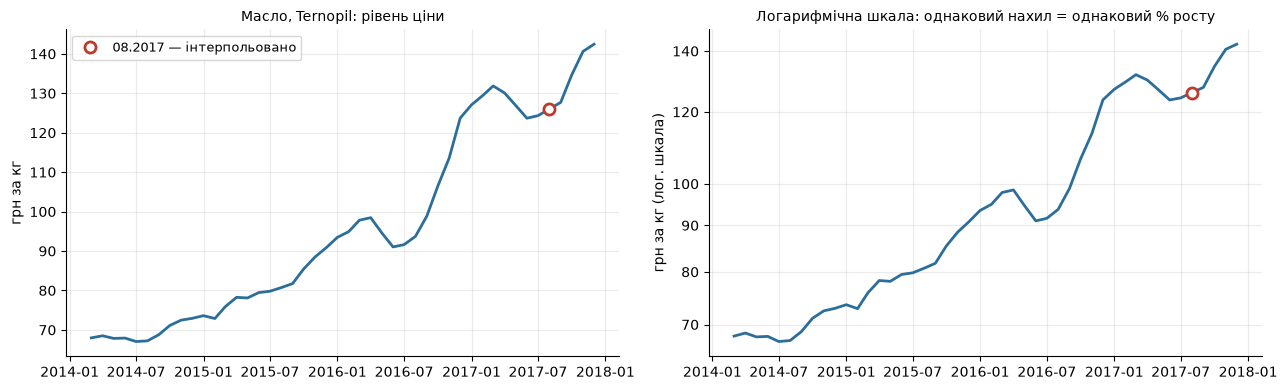

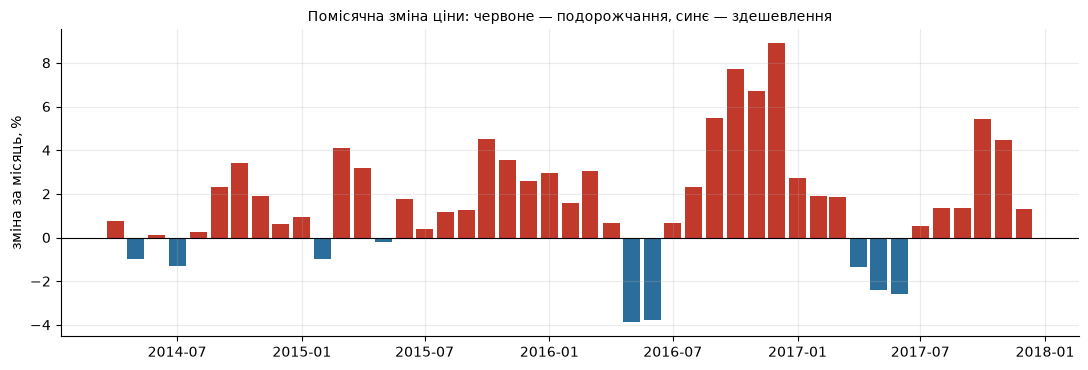

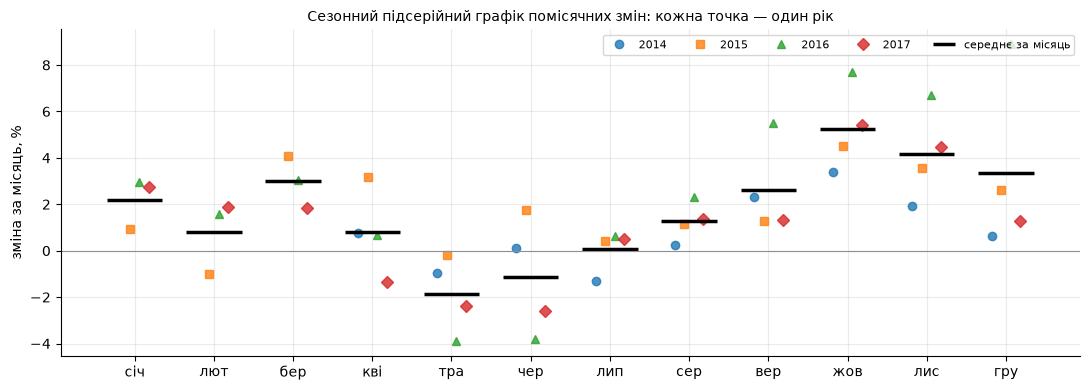

Середня помісячна зміна за календарним місяцем, %:
m
1     2.20
2     0.82
3     2.99
4     0.81
5    -1.87
6    -1.12
7     0.07
8     1.26
9     2.60
10    5.26
11    4.16
12    3.36

Ріст за 10.2016–12.2016: 25.1 %;  падіння 03.2016→06.2016: -6.9 %;  03.2017→06.2017: -6.2 %


In [5]:
# Завдання 3. Візуальна розвідка
# Графік 1: як змінювалась ціна (рівень) — лінійна та логарифмічна шкала
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, log in zip(axes, [False, True]):
    ax.plot(s.index, s.values, color=C_MAIN, lw=2)
    ax.plot([gap], [s[gap]], 'o', mfc='white', mec=C_ACC, ms=8, mew=2, label='08.2017 — інтерпольовано')
    ax.set_ylabel('грн за кг' + (' (лог. шкала)' if log else ''))
    if log:
        ax.set_yscale('log'); ax.set_yticks([70, 80, 90, 100, 120, 140]); ax.set_yticklabels([70, 80, 90, 100, 120, 140])
    ax.set_title(('Логарифмічна шкала: однаковий нахил = однаковий % росту' if log
                  else f'Масло, {MARKET}: рівень ціни'), fontsize=10)
axes[0].legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

# Графік 2: коли відбувались різкі зміни — помісячні зміни, % (стовпчики від нуля)
mom = s.pct_change().mul(100).dropna()
fig, ax = plt.subplots()
ax.bar(mom.index, mom.values, width=25, color=np.where(mom > 0, C_ACC, C_MAIN))
ax.axhline(0, color='black', lw=.8)
ax.set_ylabel('зміна за місяць, %'); ax.set_title('Помісячна зміна ціни: червоне — подорожчання, синє — здешевлення', fontsize=10)
plt.tight_layout(); plt.show()

# Графік 3: чи повторюється однаковий візерунок щороку — сезонний підсерійний графік
mom_df = pd.DataFrame({'m': mom.index.month, 'y': mom.index.year, 'v': mom.values})
fig, ax = plt.subplots(figsize=(11, 4))
for yr, mk_ in zip(sorted(mom_df.y.unique()), ['o', 's', '^', 'D']):
    d_ = mom_df[mom_df.y == yr]
    ax.plot(d_.m + (yr - 2015.5) * .12, d_.v, mk_, ms=6, alpha=.8, label=str(yr), linestyle='none')
means = mom_df.groupby('m').v.mean()
ax.hlines(means.values, means.index - .35, means.index + .35, color='black', lw=2.5, label='середнє за місяць')
ax.axhline(0, color=C_GREY, lw=.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру'])
ax.set_ylabel('зміна за місяць, %'); ax.legend(ncol=5, fontsize=8, loc='upper right')
ax.set_title('Сезонний підсерійний графік помісячних змін: кожна точка — один рік', fontsize=10)
plt.tight_layout(); plt.show()

print('Середня помісячна зміна за календарним місяцем, %:')
print(means.round(2).to_string())
print(f'\nРіст за 10.2016–12.2016: {s["2016-12-01"]/s["2016-09-01"]*100-100:.1f} %;  '
      f'падіння 03.2016→06.2016: {s["2016-06-01"]/s["2016-03-01"]*100-100:.1f} %;  '
      f'03.2017→06.2017: {s["2017-06-01"]/s["2017-03-01"]*100-100:.1f} %')

**Висновок до завдання 3:**

1. **Графік 1 — «як змінювався рівень ціни?»** Геометрія — лінія, бо це впорядковані в часі, рівномірно розташовані виміри однієї величини; лінія підкреслює неперервність і напрямок. Ліва панель має лінійну шкалу (видно абсолютні гривні: з 68 до 142 грн, тобто ×2,1), права — логарифмічну, бо для цін важливі *відносні* зміни: однаковий нахил на лог-шкалі означає однаковий темп у відсотках. Вісь Y не починається з нуля — для лінії це допустимо, бо лінія кодує зміну, а не величину довжиною. Інтерпольована точка позначена порожнім кружком, щоб не видавати її за вимір.
   **Графік 2 — «коли відбувались різкі стрибки?»** Стовпчики від нуля, бо кодується величина зміни довжиною і знак (вгору/вниз) — тут нуль є змістовним початком відліку, тому шкала обов'язково від 0; колір дублює знак.
   **Графік 3 — «чи повторюється однаковий візерунок щороку?»** Сезонний підсерійний графік: вісь X — календарний місяць, точки — окремі роки, риска — середнє. Точки (а не лінія) обрано, бо сусідні місяці тут не утворюють неперервності між роками; такий графік відокремлює сезонність від тренду, бо працює з помісячними змінами, а не з рівнем.
2. **Несподівана знахідка:** номінальна ціна масла, попри інфляцію 2015 року (~43 %), **регулярно падає навесні–влітку**: 03.2016 → 06.2016 на −7 %, 03.2017 → 06.2017 на −6 %. Тобто в ряді є виразна сезонність (весняний пік, літній мінімум, коли надоїв молока найбільше), а не лише тренд. Друга несподіванка — **стрибок +25 % лише за три місяці (10–12.2016)**, значно більший за будь-яку іншу зміну в ряді, — це кандидат на зміну режиму (завдання 8).

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

**Хід виконання.** Ряд розкладається методом STL на три складові: тренд (загальний напрямок), сезонну складову (те, що повторюється щороку в ті самі місяці) та залишок (випадкові коливання). Сума трьох складових дає вихідний ряд. Оскільки STL виділяє сезонну складову з будь-якого ряду, навіть із шуму, сам факт її появи нічого не доводить. Тому обчислюється сила сезонності F_S: вона показує, наскільки сезонна складова більша за випадкові коливання. Значення понад 0,3 свідчить про справжню сезонність. Аналогічно обчислюється сила тренду F_T.

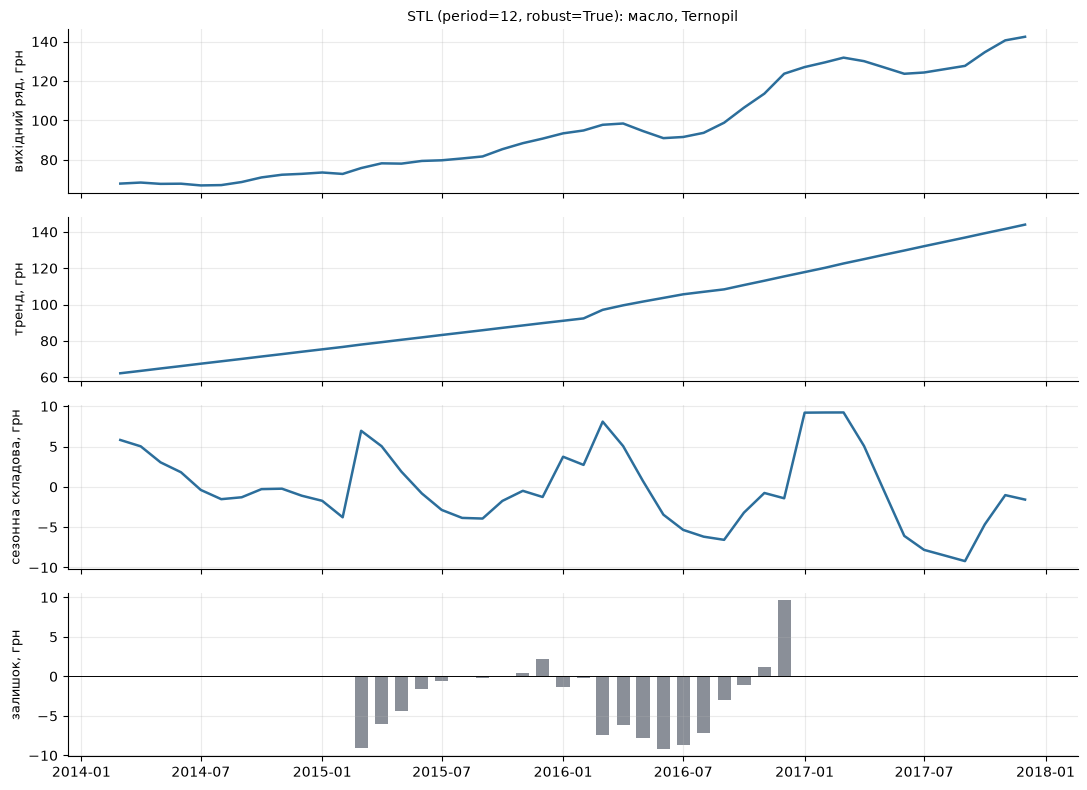

Сила сезонності F_S = 0.614   (поріг 0,3)
Сила тренду     F_T = 0.981
Перевірка стійкості (robust=False): F_S = 0.880, F_T = 0.995

Середня сезонна складова за місяцем, грн:
1     3.74
2     2.73
3     7.53
4     5.05
5     1.31
6    -2.13
7    -4.10
8    -5.02
9    -5.25
10   -2.47
11   -0.62
12   -1.34
Розмах сезонного профілю: 12.78 грн; std залишку: 3.45 грн


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL
stl = STL(s, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, comp, title in zip(axes, [s, stl.trend, stl.seasonal, stl.resid],
                           ['вихідний ряд', 'тренд', 'сезонна складова', 'залишок']):
    if title == 'залишок':
        ax.bar(comp.index, comp.values, width=20, color=C_GREY); ax.axhline(0, color='black', lw=.7)
    else:
        ax.plot(comp.index, comp.values, color=C_MAIN, lw=1.8)
    ax.set_ylabel(title + ', грн', fontsize=9)
axes[0].set_title(f'STL (period=12, robust=True): масло, {MARKET}', fontsize=10)
plt.tight_layout(); plt.show()

def strength(comp, resid):
    return max(0.0, 1 - resid.var() / (comp + resid).var())
F_S = strength(stl.seasonal, stl.resid)
F_T = strength(stl.trend, stl.resid)
print(f'Сила сезонності F_S = {F_S:.3f}   (поріг 0,3)')
print(f'Сила тренду     F_T = {F_T:.3f}')

stl_nr = STL(s, period=12, robust=False).fit()
print(f'Перевірка стійкості (robust=False): F_S = {strength(stl_nr.seasonal, stl_nr.resid):.3f}, '
      f'F_T = {strength(stl_nr.trend, stl_nr.resid):.3f}')

prof = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print('\nСередня сезонна складова за місяцем, грн:'); print(prof.round(2).to_string())
print(f'Розмах сезонного профілю: {prof.max() - prof.min():.2f} грн; std залишку: {stl.resid.std():.2f} грн')

In [ ]:
**Висновок до завдання 4:**

1. Чотирипанельний графік — вище (вихідний ряд, тренд, сезонна складова, залишок; залишок показано стовпчиками від нуля, бо це відхилення).
2. **F_S = 0,614**, **F_T = 0,981**. Перевірка без робастного зважування дає F_S = 0,880 і F_T = 0,995 — висновок не змінюється.
3. **Сезонність у ряді є.** F_S = 0,61 удвічі перевищує поріг 0,3, тобто сезонна складова пояснює значну частину варіації ряду після вилучення тренду, і це не шум. Профіль має економічний зміст: пік у **березні–квітні** (+5…+7,5 грн), мінімум у **липні–вересні** (−4…−5 грн), розмах ≈12,8 грн, що вдвічі більше за стандартне відхилення залишку. Це узгоджується з сезонністю молочного виробництва (найбільші надої влітку → дешевша сировина) і з графіком 3 із завдання 3, де травень і червень у середньому мають від'ємні помісячні зміни (−1,9 % і −1,1 %), попри загальний ріст ціни. Водночас тренд значно сильніший (F_T = 0,98): ряд передусім визначається зростанням ціни вдвічі, а сезонність — другорядний, але реальний ефект. Застереження: маємо лише ≈3,8 сезонних циклів, тому оцінка профілю для окремих місяців неточна.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

**Хід виконання.** Модель ARIMA потребує стаціонарного ряду, тобто такого, що коливається навколо сталого рівня. Ціна, яка постійно зростає, цієї умови не задовольняє. Тому перевіряється, чи стає стаціонарним ряд помісячних змін ціни (перша різниця). Для цього використовуються графіки автокореляції (ACF, PACF) і два статистичні тести з протилежними нульовими гіпотезами: ADF (H₀ — ряд нестаціонарний) і KPSS (H₀ — ряд стаціонарний). Застосування обох тестів дозволяє перевірити висновок з двох боків. Результат визначає порядок диференціювання d для моделі в завданні 7.

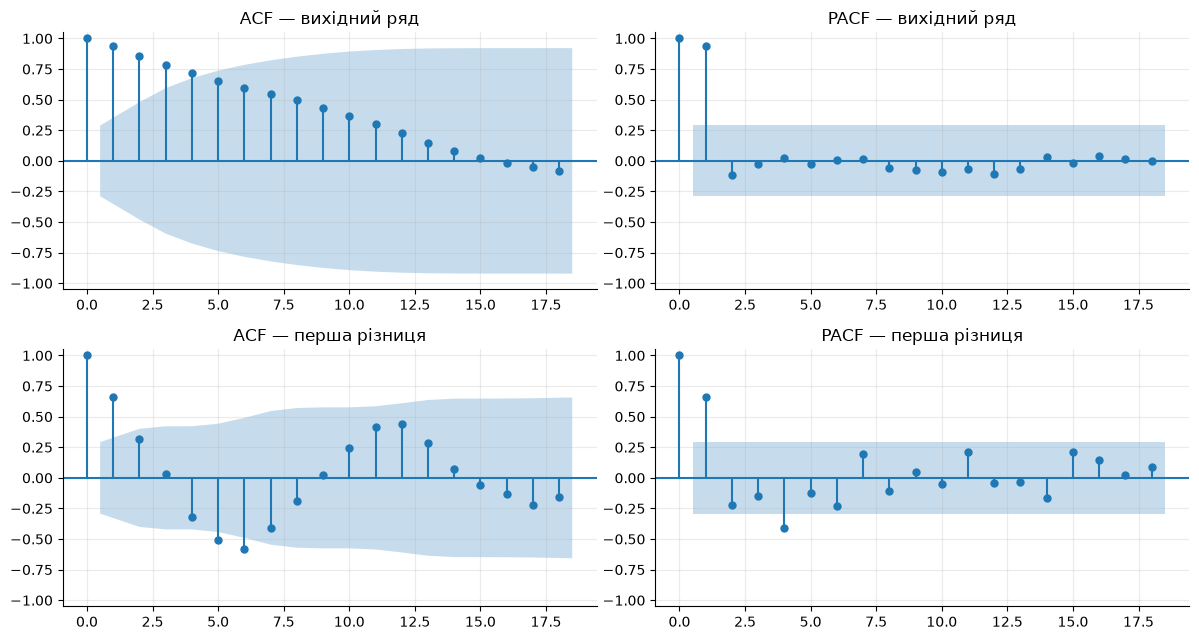

                ADF p ADF висновок (H0: нестаціонарний)  KPSS p KPSS висновок (H0: стаціонарний)
ряд                                                                                             
вихідний ряд   0.9955                    нестаціонарний    0.01                   нестаціонарний
перша різниця  0.0004                      стаціонарний    0.10                     стаціонарний

(KPSS у statsmodels табульований лише в межах 0,01…0,10: 0,01 означає «≤0,01», 0,10 — «≥0,10»)

Межа значущості ±0.29. Значущі лаги першої різниці:
  ACF : [1, 2, 4, 5, 6, 7, 11, 12]
  PACF: [1, 4]


/var/folders/tr/xtl4k7215tz2zh9tvpf0mlqh0000gn/T/ipykernel_20361/1977180498.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression='c', nlags='auto')[1]
/var/folders/tr/xtl4k7215tz2zh9tvpf0mlqh0000gn/T/ipykernel_20361/1977180498.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(x, regression='c', nlags='auto')[1]


In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

ds = s.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for row, (x, name) in enumerate([(s, 'вихідний ряд'), (ds, 'перша різниця')]):
    plot_acf(x, lags=18, ax=axes[row, 0], title=f'ACF — {name}')
    plot_pacf(x, lags=18, ax=axes[row, 1], title=f'PACF — {name}', method='ywm')
for ax in axes.flat: ax.set_ylim(-1.05, 1.05)
plt.tight_layout(); plt.show()

rows = []
for x, name in [(s, 'вихідний ряд'), (ds, 'перша різниця')]:
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    rows.append({'ряд': name, 'ADF p': round(p_adf, 4),
                 'ADF висновок (H0: нестаціонарний)': 'стаціонарний' if p_adf < .05 else 'нестаціонарний',
                 'KPSS p': round(p_kpss, 3),
                 'KPSS висновок (H0: стаціонарний)': 'нестаціонарний' if p_kpss < .05 else 'стаціонарний'})
st_tab = pd.DataFrame(rows).set_index('ряд')
print(st_tab.to_string())
print('\n(KPSS у statsmodels табульований лише в межах 0,01…0,10: 0,01 означає «≤0,01», 0,10 — «≥0,10»)')

bound = 1.96 / np.sqrt(len(ds))
a_d, p_d = acf(ds, nlags=13), pacf(ds, nlags=13, method='ywm')
print(f'\nМежа значущості ±{bound:.2f}. Значущі лаги першої різниці:')
print('  ACF :', [k for k in range(1, 14) if abs(a_d[k]) > bound])
print('  PACF:', [k for k in range(1, 14) if abs(p_d[k]) > bound])

**Висновок до завдання 5:**

1. Графіки ACF/PACF — вище. Вихідний ряд: ACF спадає повільно й майже лінійно (0,93 → 0,86 → 0,79 …, значуща до ≈7-го лагу), PACF має один великий пік на лагу 1 (0,96) — класична картина ряду з одиничним коренем / трендом. Перша різниця: ACF значуща на лагу 1 (0,66) і має хвилю — від'ємні значення на лагах 4–7 (до −0,58) та знову додатні на 11–12 (≈0,4–0,44); PACF значуща на лагах 1 (0,68) і 4 (−0,47), далі обривається.
2. Таблиця p-значень — вище: вихідний ряд ADF p ≈ 0,996, KPSS p ≤ 0,01; перша різниця ADF p ≈ 0,0004, KPSS p ≥ 0,10.
3. **Висновок:** вихідний ряд **нестаціонарний** — обидва тести це підтверджують (ADF не відхиляє H₀ про одиничний корінь, KPSS відхиляє H₀ про стаціонарність). **Перша різниця стаціонарна** — ADF відхиляє H₀ про нестаціонарність, KPSS не відхиляє H₀ про стаціонарність. **Тести узгоджуються між собою** для обох рядів, отже достатньо одного диференціювання, d = 1 (подвійне диференціювання, як у звіті колеги, було б надмірним).
4. Суперечності немає. Залишкова хвиля в ACF першої різниці з періодом ≈12 місяців — це не ознака нестаціонарності, а прояв **сезонності**, знайденої в завданні 4: тести ADF/KPSS перевіряють стохастичний тренд, а не сезонну структуру.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

**Хід виконання.** Щоб оцінити, чи має сенс складна модель, потрібна точка відліку. Нею є найпростіші прогнози: наївний (як останнє значення), сезонний наївний (як рік тому), середнє та дрейф (останнє значення плюс середній приріст). Усі вони перевіряються ретроспективно з рухомим початком: модель навчається лише на минулих даних, прогнозує наступні 3 місяці, потім початок зсувається; процедура повторюється 7 разів. Кількість фолдів і кроків збігається з налаштуваннями Orange у Частині 2. Для порівняння виконується також випадковий поділ 75/25, щоб показати, наскільки він спотворює оцінку для часового ряду.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
N_FOLDS, H = 7, 3
y = s.values; n = len(y)

def fc_naive(tr, h):  return np.repeat(tr[-1], h)
def fc_snaive(tr, h): return np.array([tr[len(tr) - 12 + (i % 12)] for i in range(h)])
def fc_mean(tr, h):   return np.repeat(tr.mean(), h)
def fc_drift(tr, h):  return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)
BASELINES = {'наївний': fc_naive, 'сезонний наївний': fc_snaive, 'середнє': fc_mean, 'дрейф': fc_drift}

def folds():
    # фолд f: навчання — усе до позиції -3f, перевірка — наступні 3; перебір у хронологічному порядку
    for f in range(N_FOLDS, 0, -1):
        end = n - H * f
        yield f, y[:end], y[end:end + H]

def rolling_eval(forecaster):
    m = {'MAE': [], 'RMSE': [], 'MAPE, %': []}
    for f, tr, te in folds():
        e = te - forecaster(tr, H)
        m['MAE'].append(np.mean(np.abs(e)))
        m['RMSE'].append(np.sqrt(np.mean(e ** 2)))
        m['MAPE, %'].append(np.mean(np.abs(e / te)) * 100)
    return {k: np.mean(v) for k, v in m.items()}   # середнє по всіх 7 фолдах

print('Фолди ретроспективної перевірки:')
for f, tr, te in folds():
    print(f'  f={f}: навчання 03.2014–{GRID[len(tr)-1]:%m.%Y} ({len(tr):2d} точок) → перевірка '
          f'{GRID[len(tr)]:%m.%Y}–{GRID[len(tr)+H-1]:%m.%Y}')

base_tab = pd.DataFrame({k: rolling_eval(fn) for k, fn in BASELINES.items()}).T
print('\nРухомий початок, 7 фолдів × 3 кроки (середнє по фолдах):')
print(base_tab.round(3).to_string())
BEST = base_tab['MAE'].idxmin()
print('\nНайкращий базис за MAE:', BEST)

# Для порівняння — випадковий поділ 75/25 (неправильний для часових рядів)
from sklearn.model_selection import train_test_split
tr_idx, te_idx = train_test_split(np.arange(n), test_size=.25, random_state=42)
tr_idx = np.sort(tr_idx)
def random_split_pred(name, i):
    prev = tr_idx[tr_idx < i]
    last = prev.max() if len(prev) else tr_idx.min()
    if name == 'наївний': return y[last]
    if name == 'сезонний наївний': return y[i - 12] if (i - 12) in tr_idx else np.nan
    if name == 'середнє': return y[tr_idx].mean()            # середнє включає «майбутні» точки
    if name == 'дрейф':                                       # нахил рахується і по майбутніх точках
        return y[last] + (y[tr_idx.max()] - y[tr_idx.min()]) / (tr_idx.max() - tr_idx.min()) * (i - last)
rnd = {}
for name in BASELINES:
    pr = np.array([random_split_pred(name, i) for i in te_idx]); ok = ~np.isnan(pr)
    e = y[te_idx][ok] - pr[ok]
    rnd[name] = {'MAE (випадк. 75/25)': np.mean(np.abs(e)), 'точок': ok.sum()}
cmp = pd.DataFrame(rnd).T
cmp['MAE (рухомий початок)'] = base_tab['MAE']
cmp['у скільки разів'] = cmp['MAE (рухомий початок)'] / cmp['MAE (випадк. 75/25)']
print('\nПорівняння з випадковим поділом 75/25:')
print(cmp.round(2).to_string())

Фолди ретроспективної перевірки:
  f=7: навчання 03.2014–03.2016 (25 точок) → перевірка 04.2016–06.2016
  f=6: навчання 03.2014–06.2016 (28 точок) → перевірка 07.2016–09.2016
  f=5: навчання 03.2014–09.2016 (31 точок) → перевірка 10.2016–12.2016
  f=4: навчання 03.2014–12.2016 (34 точок) → перевірка 01.2017–03.2017
  f=3: навчання 03.2014–03.2017 (37 точок) → перевірка 04.2017–06.2017
  f=2: навчання 03.2014–06.2017 (40 точок) → перевірка 07.2017–09.2017
  f=1: навчання 03.2014–09.2017 (43 точок) → перевірка 10.2017–12.2017

Рухомий початок, 7 фолдів × 3 кроки (середнє по фолдах):
                     MAE    RMSE  MAPE, %
наївний            6.795   7.542    5.642
сезонний наївний  25.517  25.721   21.247
середнє           33.148  33.374   27.149
дрейф              5.938   6.639    5.023

Найкращий базис за MAE: дрейф



Порівняння з випадковим поділом 75/25:
                  MAE (випадк. 75/25)  точок  MAE (рухомий початок)  у скільки разів
наївний                          2.24   12.0                   6.80             3.04
сезонний наївний                24.44    7.0                  25.52             1.04
середнє                         22.45   12.0                  33.15             1.48
дрейф                            2.01   12.0                   5.94             2.95


**Висновок до завдання 6:**

1. Таблиця для чотирьох базисів (рухомий початок, 7 × 3, середнє по фолдах): **дрейф** — MAE 5,94 грн, RMSE 6,64, MAPE 5,02 %; **наївний** — 6,80 / 7,54 / 5,64 %; **сезонний наївний** — 25,52 / 25,72 / 21,25 %; **середнє** — 33,15 / 33,37 / 27,15 %.
2. Найкращий — **дрейф**, трохи кращий за наївний (MAE менша на 13 %). Пояснення через властивості ряду: ряд має сильний **стохастичний тренд** (F_T = 0,98, одиничний корінь за ADF/KPSS) і стабільно зростає (у середньому ≈+1,7 грн/міс). Тому найкраще «останнє значення» (наївний), а дрейф ще й додає середній щомісячний приріст — для ряду, що зростає, це зменшує систематичне заниження. Сезонний наївний і середнє — катастрофічно погані: вони «прив'язані» до рівня річної давнини або до середнього за весь період, а ціна за рік зростала на 20–40 %, тобто тренд повністю перекриває сезонний ефект (≈±6 грн). Отже, хоч сезонність і є (F_S = 0,61), вона не настільки сильна, щоб прогнозувати «як рік тому».
3. Випадковий поділ 75/25 дає для наївного MAE ≈ 2,24 грн проти 6,80 на рухомому початку — **у ≈3,0 раза оптимістичніше**, для дрейфу — у ≈3,0 раза. Причина — витік інформації з майбутнього: тестові точки розкидані між навчальними, тож «прогноз» робиться на 1 місяць від найближчого відомого сусіда (а дрейф і середнє ще й використовують майбутні значення). На практиці прогнозувати доводиться на 1–3 місяці вперед від кінця ряду, тому реалістичною є лише оцінка з рухомим початком. (Для середнього й сезонного наївного випадковий поділ теж трохи «краще», але вони погані за будь-якої схеми.)

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

**Хід виконання.** Будується модель ARIMA(1,1,1) — вона прогнозує зміну ціни на основі попередньої зміни та попередньої похибки. Модель оцінюється на тих самих 7 фолдах по 3 кроки, що й базисні прогнози, тому результати можна порівнювати напряму. Додатково обґрунтовується порядок моделі, який випливає з графіків ACF і PACF завдання 5, і перевіряється його варіант із сезонною складовою. Наприкінці аналізуються залишки моделі: якщо в них лишилася закономірність, модель не вловила частину структури ряду.

                              MAE   RMSE  MAPE, %
ARIMA(1,1,1) — обов'язкова  8.596  9.508    7.290
ARIMA(1,1,0) — за ACF/PACF  8.541  9.421    7.226
SARIMA(1,1,0)(1,0,0)12      6.555  7.240    5.726
найкращий базис (дрейф)     5.938  6.639    5.023
наївний                     6.795  7.542    5.642

ARIMA(1,1,1) гірша за дрейф: MAE ×1.45, RMSE ×1.43


/Users/angelinabobrynok/Documents/uni/3/Машинне навчання/2lab/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params
/Users/angelinabobrynok/Documents/uni/3/Машинне навчання/2lab/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params
/Users/angelinabobrynok/Documents/uni/3/Машинне навчання/2lab/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params
/Users/angelinabobrynok/Documents/uni/3/Машинне навчання/2lab/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non

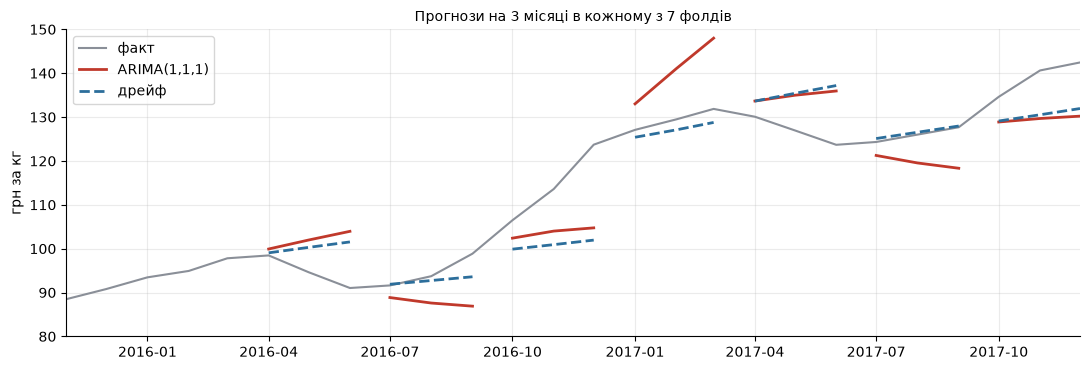

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6398      0.130      4.930      0.000       0.385       0.894
ma.L1          0.2186      0.242      0.903      0.366      -0.256       0.693
sigma2         4.6360      0.897      5.166      0.000       2.877       6.395


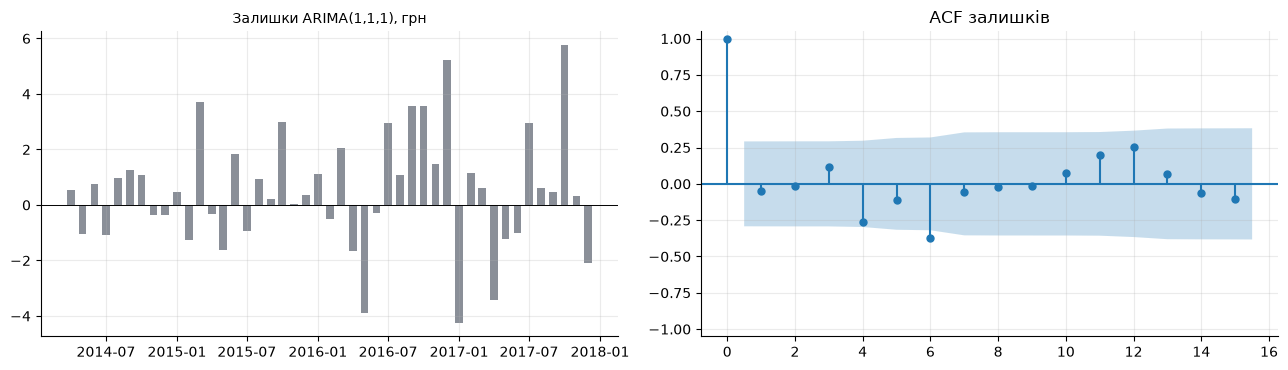

    lb_stat  lb_pvalue
6    12.535      0.051
12   19.717      0.073


In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

def fc_arima111(tr, h): return ARIMA(tr, order=(1, 1, 1)).fit().forecast(h)
def fc_arima110(tr, h): return ARIMA(tr, order=(1, 1, 0)).fit().forecast(h)
def fc_sarima(tr, h):   return SARIMAX(tr, order=(1, 1, 0), seasonal_order=(1, 0, 0, 12)).fit(disp=False).forecast(h)

models_tab = pd.DataFrame({
    'ARIMA(1,1,1) — обов\'язкова': rolling_eval(fc_arima111),
    'ARIMA(1,1,0) — за ACF/PACF': rolling_eval(fc_arima110),
    'SARIMA(1,1,0)(1,0,0)12': rolling_eval(fc_sarima),
    f'найкращий базис ({BEST})': base_tab.loc[BEST].to_dict(),
    'наївний': base_tab.loc['наївний'].to_dict()}).T
print(models_tab.round(3).to_string())
r111 = models_tab.iloc[0]
print(f'\nARIMA(1,1,1) гірша за {BEST}: MAE ×{r111["MAE"] / base_tab.loc[BEST, "MAE"]:.2f}, '
      f'RMSE ×{r111["RMSE"] / base_tab.loc[BEST, "RMSE"]:.2f}')

# Прогнози по фолдах (для наочності)
fig, ax = plt.subplots()
ax.plot(s.index, y, color=C_GREY, lw=1.5, label='факт')
for k, (f, tr, te) in enumerate(folds()):
    idx = GRID[len(tr):len(tr) + H]
    ax.plot(idx, fc_arima111(tr, H), color=C_ACC, lw=2, label='ARIMA(1,1,1)' if k == 0 else None)
    ax.plot(idx, fc_drift(tr, H), color=C_MAIN, lw=2, ls='--', label='дрейф' if k == 0 else None)
ax.set_xlim(GRID[20], GRID[-1]); ax.set_ylim(80, 150); ax.legend(); ax.set_ylabel('грн за кг')
ax.set_title('Прогнози на 3 місяці в кожному з 7 фолдів', fontsize=10)
plt.tight_layout(); plt.show()

# Залишки моделі на всьому ряді
full111 = ARIMA(y, order=(1, 1, 1)).fit()
print(full111.summary().tables[1])
res = pd.Series(full111.resid[1:], index=GRID[1:])   # перший залишок = сам рівень (артефакт d=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(res.index, res.values, width=20, color=C_GREY); axes[0].axhline(0, color='black', lw=.7)
axes[0].set_title('Залишки ARIMA(1,1,1), грн', fontsize=10)
plot_acf(res, lags=15, ax=axes[1], title='ACF залишків'); axes[1].set_ylim(-1.05, 1.05)
plt.tight_layout(); plt.show()
print(acorr_ljungbox(res, lags=[6, 12]).round(3))

**Висновок до завдання 7:**

1. **ARIMA(1,1,1)** на рухомому початку (7 × 3): **MAE = 8,60 грн, RMSE = 9,51 грн, MAPE = 7,29 %**.
2. Самостійно було б обрано **ARIMA(1,1,0)**, а з урахуванням сезонності — **SARIMA(1,1,0)(1,0,0)₁₂**. Обґрунтування: d = 1 — бо вихідний ряд нестаціонарний, а перша різниця стаціонарна за обома тестами (завдання 5). Для першої різниці PACF має найбільший пік на **лагу 1** (0,68), а ACF спадає поступово (0,66 → 0,32 → 0,03), а не обривається — це ознака AR(1), а не MA, тому q = 0. Значуща ACF на **лагах 11–12** (0,41–0,44) і від'ємна хвиля на лагах 4–7 вказують на сезонний AR-член з періодом 12. На тих самих фолдах: ARIMA(1,1,0) — MAE 8,54; SARIMA — MAE 6,56, тобто сезонна складова справді допомагає.
3. **Порівняння з найкращим базисом:** ARIMA(1,1,1) **програє дрейфу** (MAE 8,60 проти 5,94, тобто в 1,45 раза гірше) і навіть простому наївному прогнозу (6,80). Навіть найкраща з моїх моделей (SARIMA, 6,56) не перевершила дрейф. Прямий висновок: **у такому вигляді ARIMA(1,1,1) не має права на існування як прогнозна модель для цього ряду** — вона складніша й при цьому гірша за «останнє значення + середній приріст». Причина видна на графіку фолдів: без константи (за d = 1 statsmodels не додає дрейф) і з AR-коефіцієнтом 0,64 модель екстраполює *останній* імпульс — після весняного піку 2017 року вона прогнозує подальше падіння, а після літнього мінімуму недооцінює відскок; дрейф натомість закладає довгостроковий ріст.
4. Залишки: на графіку немає тренду, але видно хвилю — серію додатних залишків у 10.2016–01.2017 (стрибок рівня) і від'ємних навесні–влітку. Тест Льюнга–Бокса: p = 0,051 (лаг 6) і 0,073 (лаг 12) — **на межі** 0,05: формально білий шум не відкидається, але p близькі до порогу, а в ACF залишків є помітні значення на сезонних лагах. Тобто **в залишках лишилась сезонна структура**, яку ARIMA(1,1,1) не моделює, — це узгоджується з тим, що SARIMA дала кращий результат.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

**Хід виконання.** На графіках завдання 3 помітно різке зростання ціни наприкінці 2016 року, після якого ціна не повернулася до попереднього рівня. Щоб знайти момент такої зміни рівня, ряд почергово розрізається в кожному можливому місяці, і середні значення до і після порівнюються t-тестом; обирається розріз з найбільшою t-статистикою. Оскільки в ряду з трендом середні «до» і «після» відрізняються за будь-якого розрізу, значущість додатково перевіряється на модельованих рядах із таким самим ростом, але без зламу. Знайдена точка також порівнюється із сезонними піками, щоб відрізнити зміну рівня від звичайних щорічних коливань.

Точка зміни рівня: 12.2016   |t| = 16.90   p (наївне, t-тест Велча) = 2.2e-20
Середнє до: 82.77 грн (33 міс.)   після: 129.89 грн (13 міс.)


Монте-Карло (500 випадкових блукань із дрейфом): 95-й перцентиль max|t| = 16.74, p = 0.042
На сезонно скоригованому ряді: 11.2016, |t| = 14.25
Приріст 09.2016→12.2016: +24.85 грн; очікувана сезонна зміна за ці місяці: +3.91 грн


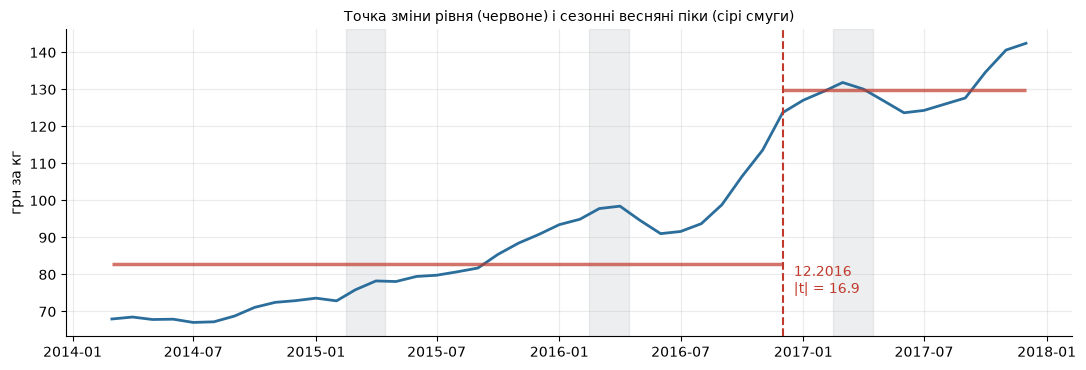

In [10]:
# Завдання 8. Точка зміни режиму
MIN_SEG = 6
def scan_level(x):
    best_k, best_t = None, 0.0
    for k in range(MIN_SEG, len(x) - MIN_SEG):
        t = stats.ttest_ind(x[:k], x[k:], equal_var=False).statistic
        if abs(t) > abs(best_t): best_k, best_t = k, t
    return best_k, best_t

k_cp, t_cp = scan_level(y)
cp_date = GRID[k_cp]
m_before, m_after = y[:k_cp].mean(), y[k_cp:].mean()
p_naive = stats.ttest_ind(y[:k_cp], y[k_cp:], equal_var=False).pvalue
print(f'Точка зміни рівня: {cp_date:%m.%Y}   |t| = {abs(t_cp):.2f}   p (наївне, t-тест Велча) = {p_naive:.1e}')
print(f'Середнє до: {m_before:.2f} грн ({k_cp} міс.)   після: {m_after:.2f} грн ({n - k_cp} міс.)')

# Чесна перевірка значущості: який max|t| дає скан на випадкових блуканнях з тим самим дрейфом
rng = np.random.default_rng(42); d1 = np.diff(y)
null_t = np.array([abs(scan_level(np.cumsum(rng.normal(d1.mean(), d1.std(), n)))[1]) for _ in range(500)])
p_mc = np.mean(null_t >= abs(t_cp))
print(f'Монте-Карло (500 випадкових блукань із дрейфом): 95-й перцентиль max|t| = {np.percentile(null_t, 95):.2f}, p = {p_mc:.3f}')

# Скан на сезонно скоригованому ряді та на приростах
sa = (s - stl.seasonal).values
k_sa, t_sa = scan_level(sa)
print(f'На сезонно скоригованому ряді: {GRID[k_sa]:%m.%Y}, |t| = {abs(t_sa):.2f}')
q4 = s['2016-12-01'] - s['2016-09-01']
print(f'Приріст 09.2016→12.2016: +{q4:.2f} грн; очікувана сезонна зміна за ці місяці: '
      f'{prof[12] - prof[9]:+.2f} грн')

fig, ax = plt.subplots()
ax.plot(s.index, y, color=C_MAIN, lw=2)
ax.axvline(cp_date, color=C_ACC, ls='--', lw=1.5)
ax.hlines(m_before, GRID[0], cp_date, color=C_ACC, lw=2.5, alpha=.7)
ax.hlines(m_after, cp_date, GRID[-1], color=C_ACC, lw=2.5, alpha=.7)
ax.annotate(f'{cp_date:%m.%Y}\n|t| = {abs(t_cp):.1f}', (cp_date, 75), xytext=(8, 0), textcoords='offset points', color=C_ACC)
for yr in [2015, 2016, 2017]:
    ax.axvspan(pd.Timestamp(f'{yr}-02-15'), pd.Timestamp(f'{yr}-04-15'), color=C_GREY, alpha=.15)
ax.set_ylabel('грн за кг'); ax.set_title('Точка зміни рівня (червоне) і сезонні весняні піки (сірі смуги)', fontsize=10)
plt.tight_layout(); plt.show()

**Висновок до завдання 8:**

1. Графік — вище: червона пунктирна лінія позначає знайдену дату, горизонтальні відрізки — середні до і після.
2. Знайдена точка — **грудень 2016 року**, **|t| ≈ 16,9**; середній рівень **до — 82,77 грн**, **після — 129,89 грн** (+57 %).
3. **Значущість.** Наївний t-тест дає p ≈ 10⁻²⁰, але це p-значення **недійсне**: (а) дату обрано як максимум серед 34 кандидатів (множинне порівняння), (б) спостереження автокорельовані, (в) у ряді з трендом середні «до» і «після» відрізняються за будь-якого поділу. Чесніше порівняти з тим, що дає той самий скан на випадкових блуканнях із тим самим дрейфом і волатильністю: 95-й перцентиль max|t| там ≈16,7, а p ≈ 0,04. Отже, точка **формально значуща на рівні 5 %, але ледь-ледь** — значна частина «стрибка» середніх пояснюється самим трендом, і на рівні 1 % вона вже не була б значущою. Проте на сезонно скоригованому ряді скан дає майже ту саму дату (11.2016), а сам стрибок 09→12.2016 (+24,9 грн, +25 %) — найбільший тримісячний приріст у ряді, тож зміна режиму росту в кінці 2016 року реальна. Зовнішнє пояснення правдоподібне: світовий бум цін на вершкове масло восени 2016 – 2017 (дефіцит молочного жиру в ЄС) і підвищення мінімальної зарплати в Україні вдвічі з 01.01.2017.
4. **Відмінність від сезонного сплеску.** Сезонні піки (сірі смуги) припадають на **лютий–квітень щороку** і змінюються на спад улітку — ціна повертається вниз. Знайдена точка: (а) у **жовтні–грудні**, коли сезонна складова, навпаки, нейтральна або від'ємна (очікувана сезонна зміна 09→12 ≈ +3,9 грн проти фактичних +24,9), (б) трапилась **один раз**, (в) після неї ціна **не повертається** до попереднього рівня. Це ознаки зсуву рівня, а не сезону.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

**Хід виконання.** Розглядається звіт, виконаний іншим студентом на ряді цін на гречку у Вінницькій області. Звіт виконується без помилок і має переконливий вигляд, але містить методологічні помилки роботи з часовими рядами. Для кожної клітинки звіту перевіряється, чи дотримано принципів, застосованих у завданнях 1–8: чи підготовлено сітку, чи правильно прочитано тести, чи коректно перевірено прогноз, чи обґрунтовано висновки. Кілька тверджень колеги перевіряються кількісно на тих самих даних.

In [11]:
# Завдання 9. Рецензія на чужий аналіз — кількісна перевірка кількох тверджень колеги
buck = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')]
        .set_index('date')['ціна'].sort_index())
print('Колега: 45 спостережень, «пропусків немає». Після reindex на сітку:',
      buck.reindex(GRID).isna().sum(), 'пропуск(и) —', [d.strftime('%m.%Y') for d in buck.reindex(GRID)[lambda x: x.isna()].index])
bk = buck.reindex(GRID).interpolate()

beef = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Meat (beef) - Retail')]
        .set_index('date')['ціна'].sort_index().reindex(GRID).interpolate())
for name, x in [('гречка', bk), ('яловичина', beef)]:
    e = x.diff().dropna().abs()
    print(f'{name:10s} MAE наївного = {e.mean():.2f} грн, середня ціна {x.mean():.1f} грн → відносна похибка {e.mean() / x.mean() * 100:.1f} %')

lv = (prices[(prices['ринок'] == 'Lviv') & (prices['товар'] == 'Buckwheat grits - Retail')]
      .set_index('date')['ціна'].sort_index().reindex(GRID).interpolate())
print(f'Кореляція рівнів r = {bk.corr(lv):.3f};  кореляція помісячних змін r = {bk.diff().corr(lv.diff()):.3f}')

stl_b = STL(bk, period=12, robust=True).fit()
print(f'Гречка: F_S = {strength(stl_b.seasonal, stl_b.resid):.3f} (колега стверджує «ряд сезонний»), '
      f'ADF p = {adfuller(bk)[1]:.3f}, KPSS p = {kpss(bk, nlags="auto")[1]:.3f}')

fc_b = ARIMA(bk.values, order=(2, 2, 1)).fit().forecast(12)
print(f'Прогноз ARIMA(2,2,1) колеги: 01.2018 = {fc_b[0]:.2f}, 12.2018 = {fc_b[-1]:.2f}, останній факт = {bk.iloc[-1]:.2f}')

Колега: 45 спостережень, «пропусків немає». Після reindex на сітку: 1 пропуск(и) — ['08.2017']
гречка     MAE наївного = 1.35 грн, середня ціна 21.4 грн → відносна похибка 6.3 %
яловичина  MAE наївного = 1.47 грн, середня ціна 79.0 грн → відносна похибка 1.9 %
Кореляція рівнів r = 0.996;  кореляція помісячних змін r = 0.937
Гречка: F_S = 0.262 (колега стверджує «ряд сезонний»), ADF p = 0.348, KPSS p = 0.018
Прогноз ARIMA(2,2,1) колеги: 01.2018 = 17.31, 12.2018 = 9.48, останній факт = 17.67


**Висновок до завдання 9:**

**1. Перелік помилок** (номери — клітинки зошита `ЛР4_помилковий_аналіз.ipynb`, рахуючи з 0):

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 1, 3 | Ряд не приведено до повної місячної сітки (45 точок замість 46); `isna().sum() = 0` перевіряє пропуски лише серед наявних рядків, тож пропуск 08.2017 «зник». | Після липня 2017 усі лаги зсунуті на місяць; STL із period=12 і сезонний наївний прогноз порівнюють не ті місяці. Висновок «даних повні» — хибний. |
| 2 | 5 | Подорожчання оцінено за двома крайніми точками в номінальних гривнях, і з цього зроблено висновок про купівельну спроможність. | Дві точки чутливі до сезонності й шуму (березень vs грудень); без інфляції та доходів не можна говорити про купівельну спроможність — у 2014–2015 зарплати теж зростали, гривня девальвувала. |
| 3 | 7 | MAE в гривнях порівнюється між товарами з різним рівнем цін; до того ж питання клітинки («чи виняткове подорожчання») не відповідає тому, що рахується (точність прогнозу). | MAE залежить від масштабу: яловичина дорожча в рази, і у відносних одиницях її прогнозувати **легше**: 1,9 % проти 6,3 % у гречки — висновок колеги протилежний правильному. Потрібні MAPE/MASE. |
| 4 | 9 | Кореляція рівнів двох трендових рядів r = 0,996 інтерпретована як причиновий зв'язок («Львів визначає Вінницю»). | Хибна (ілюзорна) кореляція: будь-які два ряди зі спільним трендом (інфляцією) корелюють; кореляція помісячних змін (0,94) — це вже інша величина, і вона теж не доводить напрямку впливу (обидва ряди реагують на спільні чинники). Кореляція не означає причинності і не вказує напрямок. |
| 5 | 11 | Сезонність «доведено» тим, що STL виділив сезонну складову; F_S не обчислено. Амплітуда в гривнях на трендовому ряді не є мірою сили. | STL повертає сезонну складову для будь-якого ряду. Для цієї гречки F_S = 0,26 < 0,3 — **сезонності фактично немає**, а далі обрано «сезонні моделі» без підстав. |
| 6 | 13 | Інвертовано висновок ADF: p = 0,233 > 0,05 → H₀ (нестаціонарність) **не відхиляється**, тож ряд **нестаціонарний**, а не стаціонарний. KPSS у парі не застосовано. | Модель для «стаціонарного» ряду на нестаціонарних даних дає хибні прогнози та довірчі інтервали. |
| 7 | 13 | Подвійне диференціювання «для надійності» без перевірки першої різниці. | Надмірне диференціювання вносить штучну від'ємну автокореляцію і зайвий MA-корінь, роздуває дисперсію прогнозу (наслідок видно в клітинці 19). |
| 8 | 15 | «Аномалії» шукаються на вихідному ряді, а не в залишках після зняття тренду й сезонності; поріг 1,3σ, хоча в тексті заявлено 2σ. | Позначено просто найдешевший початок ряду (03–11.2014) і літо 2016 — це тренд і сезон, а не «нетипові події». 12 «аномалій» з 45 — абсурд. |
| 9 | 17 | Випадковий поділ `train_test_split` для часового ряду; потім модель навчається на «перемішаних» точках, а прогноз за кінець ряду порівнюється з **відсортованими** тестовими значеннями з середини ряду. | Витік майбутнього в навчання і повністю безглузде зіставлення прогнозу з фактом — MAE 8,73 не означає нічого. |
| 10 | 17 | Базис (сезонний наївний) оцінено на іншій вибірці (in-sample на всьому ряді), наївного базису немає; MAE 8,73 грн при ціні ~15–17 грн (≈50 %) названо «високою точністю». | Порівняння незіставне; висновок про точність протилежний реальності. |
| 11 | 19 | Остаточний прогноз зроблено моделлю **(2,2,1)**, хоча оцінювали (1,1,1); горизонт 12 міс. не перевірявся; немає довірчих інтервалів. Прогноз на 12.2018 (≈8,95 грн) **нижчий** за останній факт (17,67), а висновок — «ціна продовжить зростати». | Оцінювалась одна модель, використано іншу; текст прямо суперечить числам. |
| 12 | 21 | Стовпчиковий графік з обрізаною віссю Y (від 0,995·min) і вибраним вручну півріччям. | Для стовпчиків довжина кодує величину, тож обрізана вісь візуально перебільшує зміну в десятки разів; вибір вікна — «вишенька на торті» (cherry-picking). |
| 13 | 22 | Загальні висновки повторюють усі хибні твердження (сезонність, стаціонарність, причинність, «висока точність»). | Помилки поширюються в рішення читача. |

**2. Як виправити три найсерйозніші:**

* **Випадковий поділ і зіставлення з відсортованим тестом (клітинка 17).** Замінити на ретроспективну перевірку з рухомим початком (як у завданні 6: 7 фолдів × 3 кроки, навчальна частина — усе до позиції −3f), рахувати метрики для ARIMA і для наївного / дрейфового базисів на **тих самих** фолдах і лише тоді робити висновок, чи модель краща за базис. Відносну похибку подати через MAPE/MASE.
* **Інвертований ADF і подвійне диференціювання (клітинка 13).** Правильно прочитати ADF (p = 0,233 → нестаціонарний), застосувати KPSS у парі, протестувати першу різницю; якщо вона стаціонарна — d = 1. Порядок p, q обирати за ACF/PACF першої різниці.
* **Пропуск і сітка (клітинки 1, 3).** Зробити `reindex(pd.date_range('2014-03-01','2017-12-01', freq='MS'))`, виявити пропуск 08.2017, заповнити лінійною інтерполяцією й лише потім виконувати STL, ACF і будь-які лагові обчислення. (Альтернативно небезпечна помилка — клітинка 19: використовувати ту саму модель, що оцінювалась, і перевіряти, чи напрямок прогнозу узгоджується з текстом висновку.)

Числова перевірка в клітинці вище підтверджує ключові твердження: у гречки Вінниччини є пропуск 08.2017; F_S = 0,26 (сезонності немає); ADF p ≈ 0,35 і KPSS p ≈ 0,02 — ряд нестаціонарний; у відносних одиницях яловичина прогнозується краще за гречку; а прогноз (2,2,1) спадає з 17,3 до ≈9,5 грн, тобто нижче поточної ціни.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

**Хід виконання.** Підготовлений ряд зберігається у файл для Orange у строго заданому форматі: стовпець дати у вигляді РРРР-ММ-ДД і стовпець ціни з уже заповненим пропуском. Це потрібно для того, щоб Orange отримав точно ті самі 46 значень, що й Python, і розпізнав дату як часову змінну. Після збереження файл зчитується повторно для перевірки кількості рядків і відсутності порожніх значень.

In [12]:
# Завдання 10. Експорт ряду для Orange
export = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values.round(4)})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')
print('Рядків даних:', len(check), '| стовпці:', list(check.columns), '| порожніх значень:', int(check.isna().sum().sum()))
print('Дати унікальні й ідуть щомісяця без пропусків:',
      (pd.to_datetime(check['date']) == GRID).all())
print('Значення 08.2017 у файлі:', check.loc[check['date'] == '2017-08-01', 'price'].item())
assert len(check) == 46 and check.isna().sum().sum() == 0
with open('ряд_для_orange.csv', encoding='utf-8') as fh:
    print('\nПерші рядки файлу:'); print(''.join(fh.readlines()[:4]))

Рядків даних: 46 | стовпці: ['date', 'price'] | порожніх значень: 0
Дати унікальні й ідуть щомісяця без пропусків: True
Значення 08.2017 у файлі: 126.0

Перші рядки файлу:
date,price
2014-03-01,67.9767
2014-04-01,68.5033
2014-05-01,67.8367



**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено поруч із зошитом: **46 рядків даних + заголовок**, стовпці `date` (формат `РРРР-ММ-ДД`, перше число місяця) і `price`, роздільник — кома, UTF-8. Повторне зчитування підтвердило: порожніх значень **0**, дати утворюють безперервну місячну сітку 03.2014–12.2017, а серпень 2017 містить інтерпольоване значення **126,0**. Отже, Orange отримає рівно ті самі дані, що й Python.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

> **Важливо (з коду Orange3-Timeseries):** віджети моделей вимагають **цільову змінну**. У віджеті **File** у стовпці *Role* для `price` оберіть **target** — інакше ARIMA Model видасть помилку «no target».

**Хід виконання.** У Частині 2 той самий аналіз відтворюється засобами Orange з додатком Timeseries. Спочатку будується базовий потік: завантаження файлу, перетворення таблиці на часовий ряд, інтерполяція та графік. Збіг графіка в Orange з графіком із завдання 3 підтверджує, що обидва середовища працюють з однаковими даними. Ціна позначається як цільова змінна, оскільки без цього віджети моделей Orange не працюють.

Ряд із файлу збігається з рядом у зошиті: True
min = 67.05 (07.2014), max = 142.45 (12.2017)


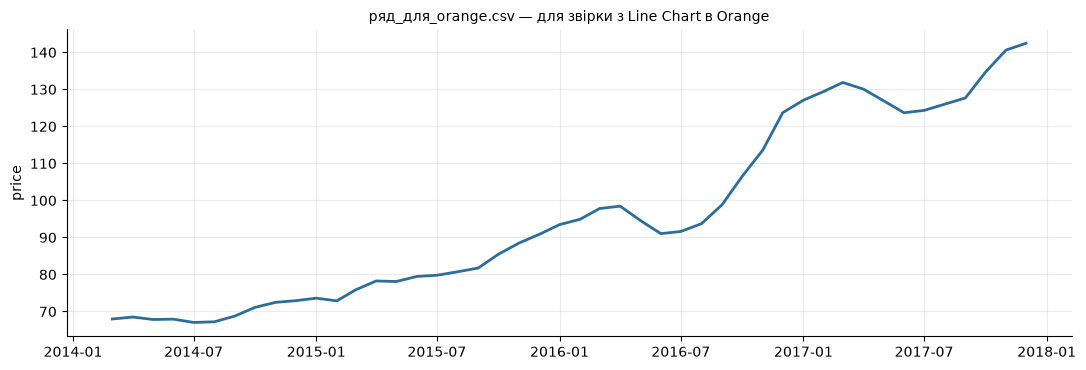

In [13]:
# Завдання 11. Контроль у Python: графік із файлу, який отримає Orange, має бути ідентичним графіку з завдання 3
chk = pd.read_csv('ряд_для_orange.csv', parse_dates=['date']).set_index('date')['price']
print('Ряд із файлу збігається з рядом у зошиті:', np.allclose(chk.values, s.values))
print(f'min = {chk.min():.2f} ({chk.idxmin():%m.%Y}), max = {chk.max():.2f} ({chk.idxmax():%m.%Y})')
fig, ax = plt.subplots()
ax.plot(chk.index, chk.values, color=C_MAIN, lw=2)
ax.set_ylabel('price'); ax.set_title('ряд_для_orange.csv — для звірки з Line Chart в Orange', fontsize=10)
plt.tight_layout(); plt.show()

**Висновок до завдання 11:**

**Знімок 1. Потік опрацювання даних в Orange:**

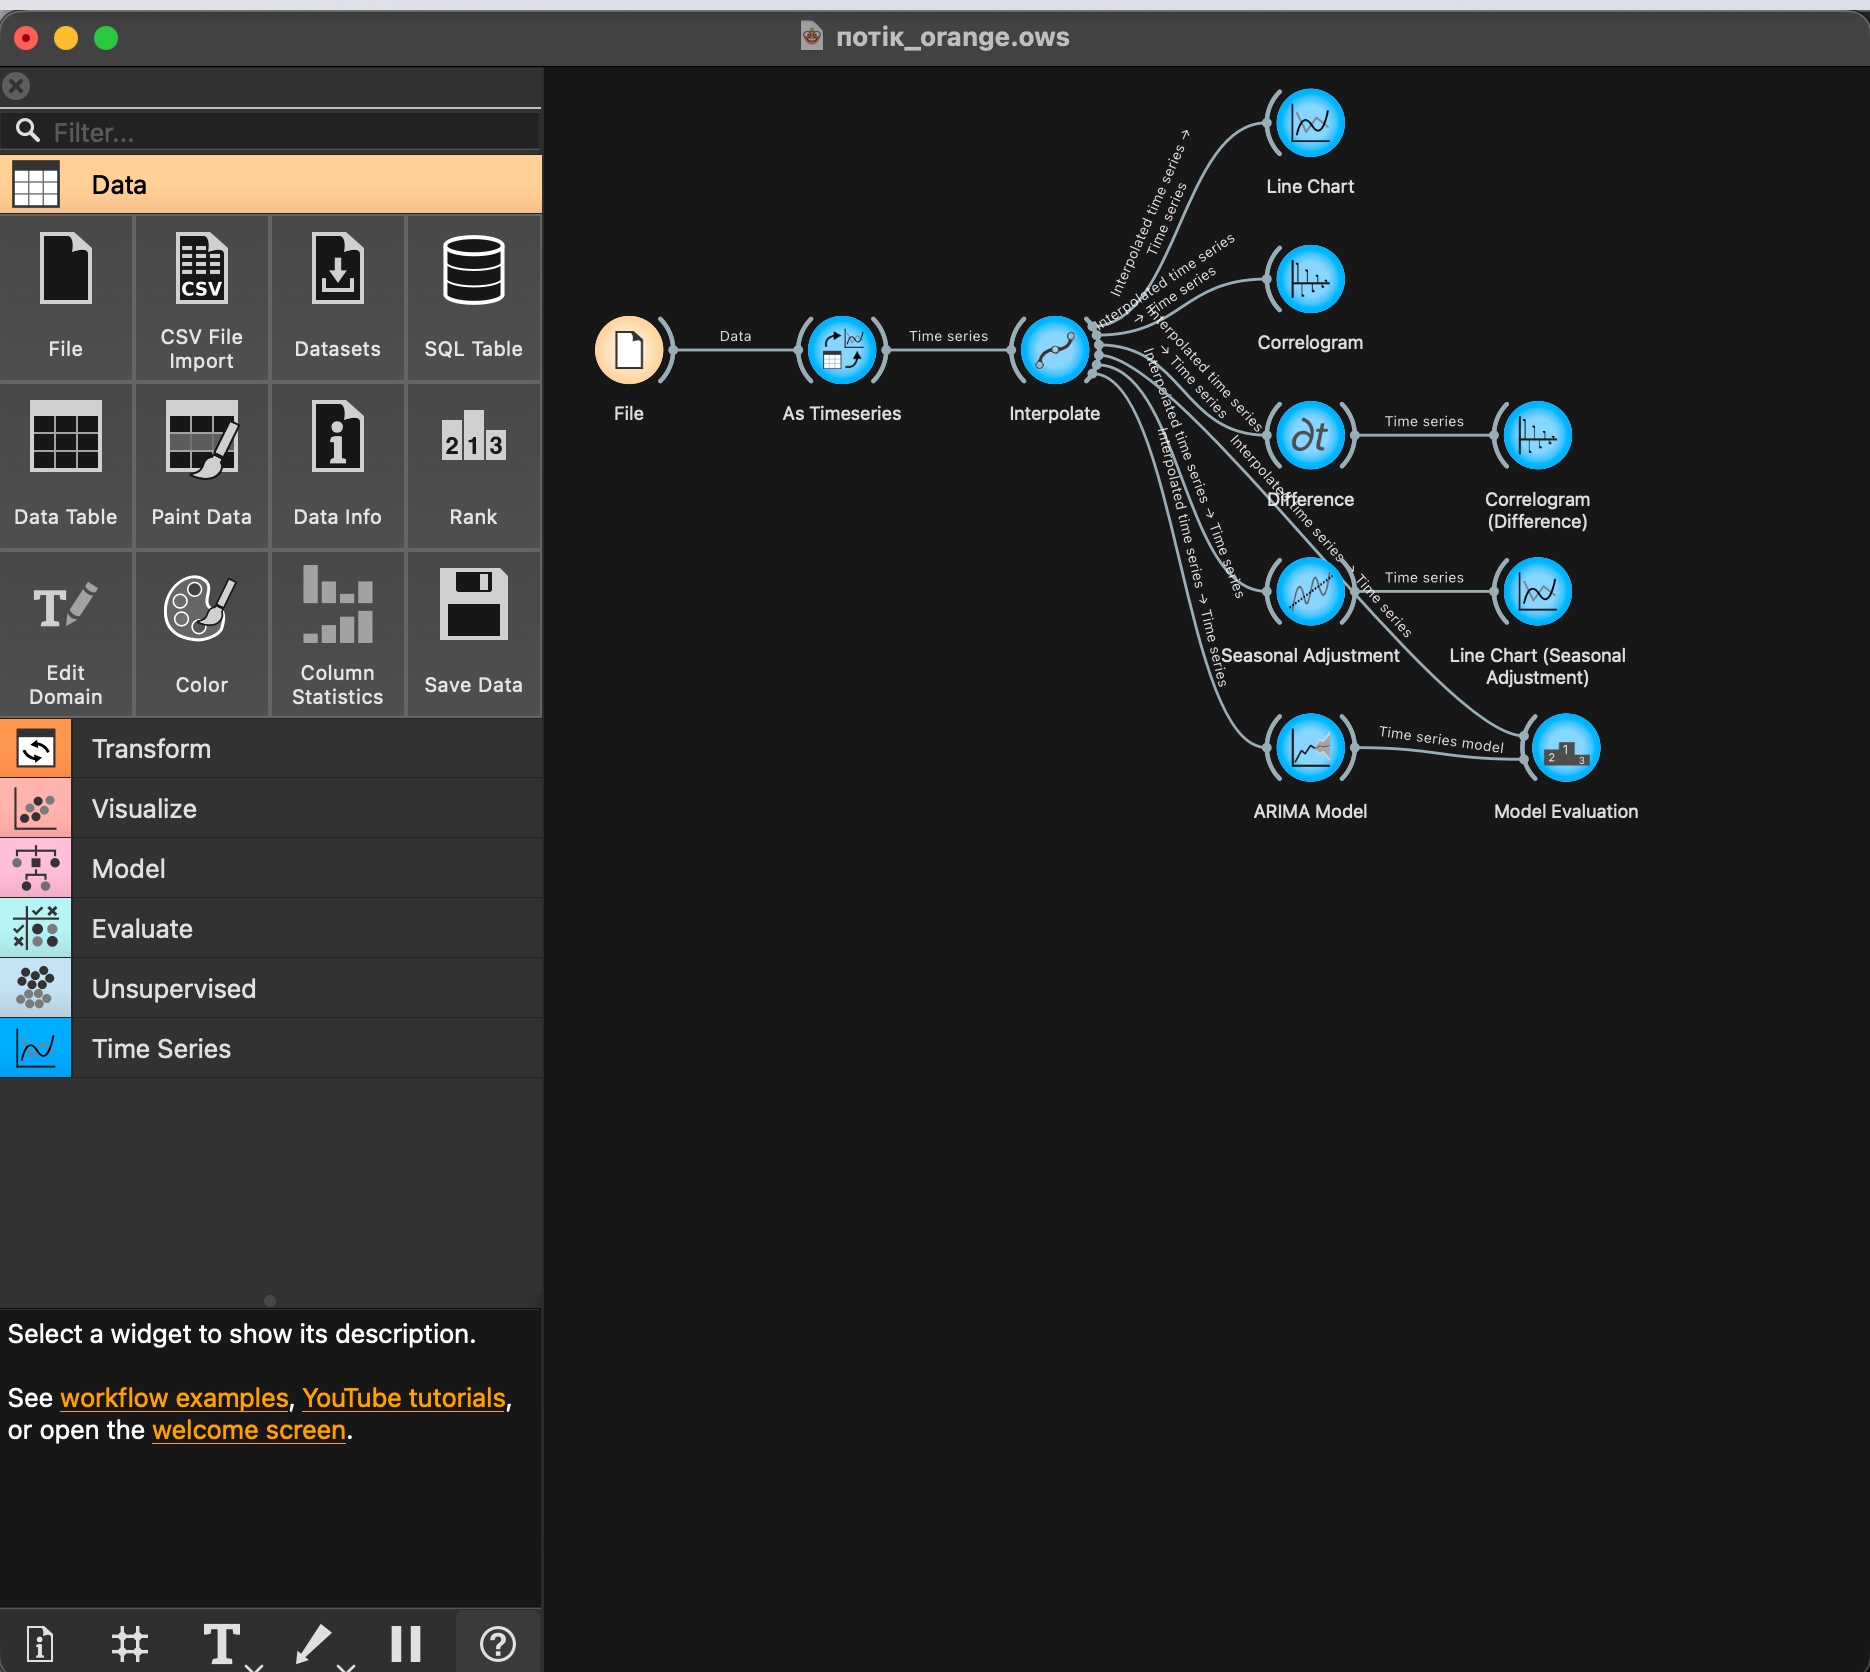

**Знімок 2. Віджет File:** `date` розпізнано як datetime (time), `price` — numeric, роль змінено на target (напис «Data has no target variable» в Info стосується файлу до редагування ролей).

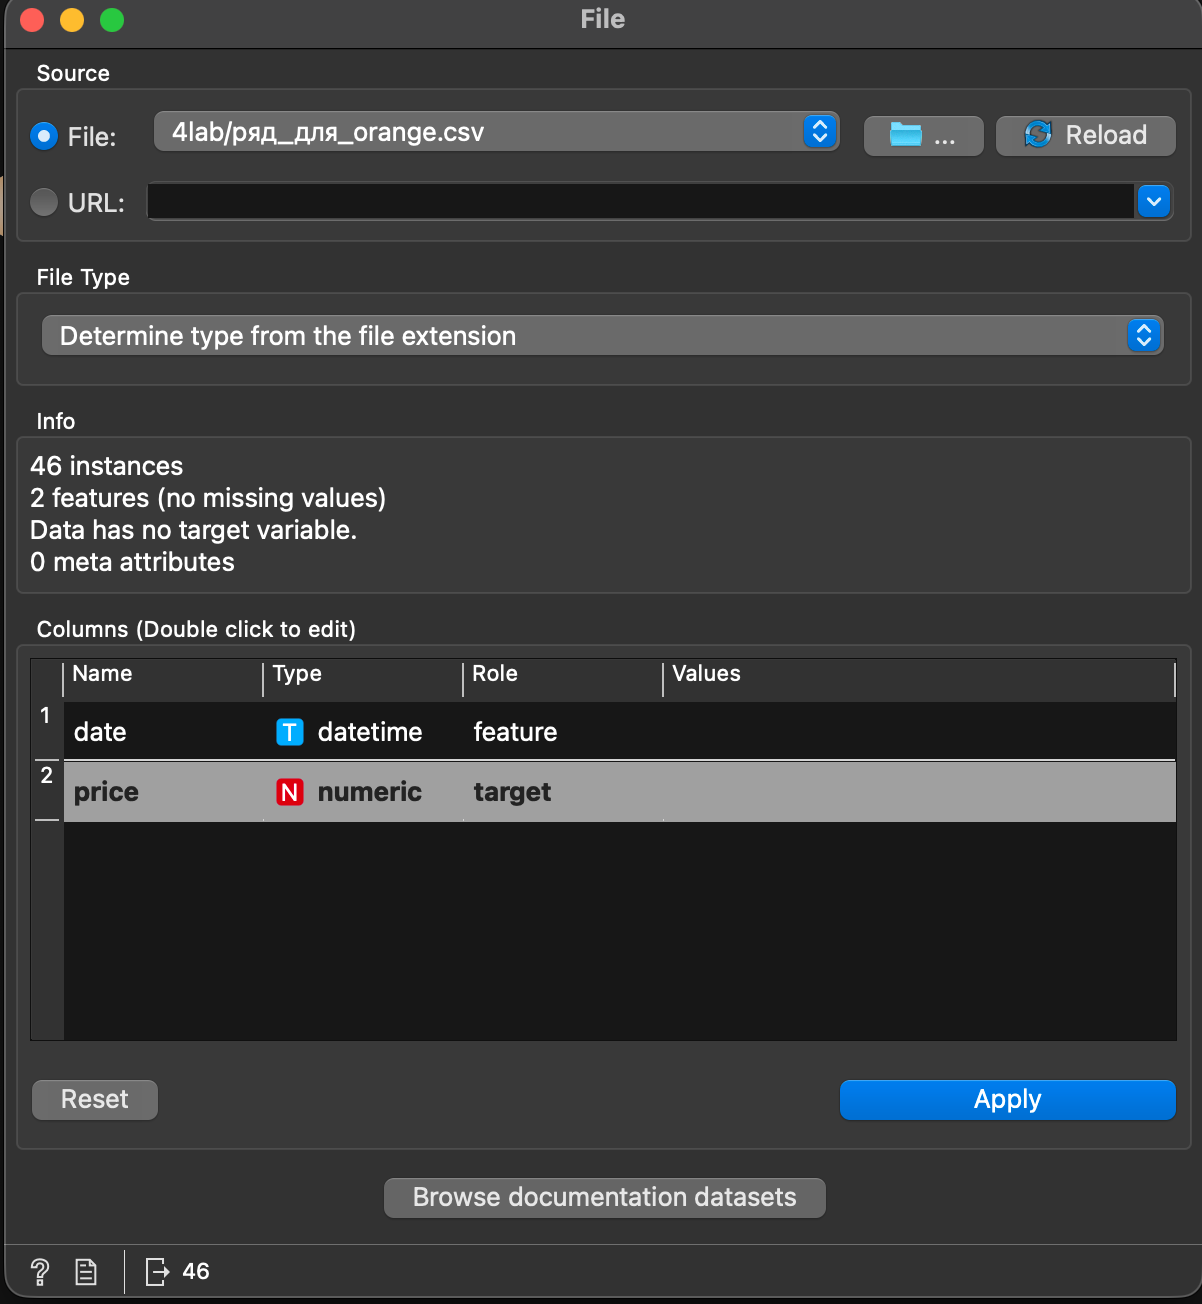

**Знімок 3. Line Chart в Orange:**

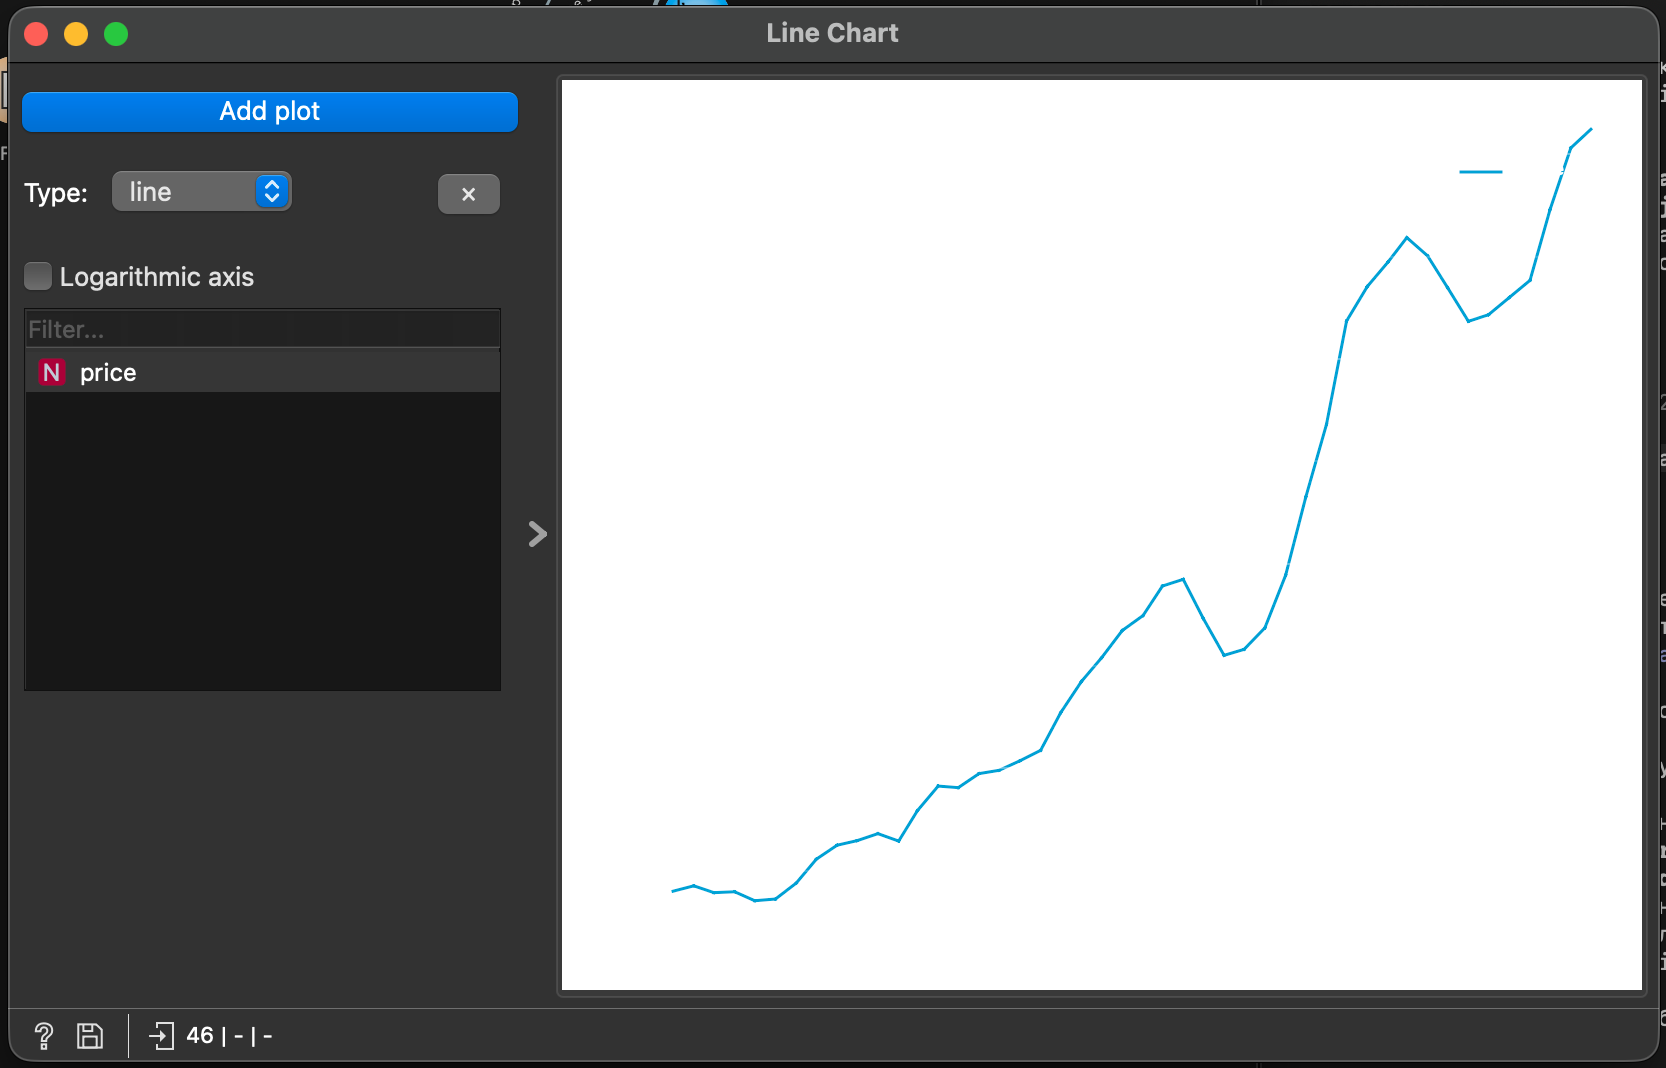

У віджеті File стовпець `date` розпізнано як **time**, `price` — як **numeric** (роль — target). Графік Line Chart в Orange **збігається** з графіком із завдання 3 і з контрольним графіком вище: та сама форма, мінімум 67,05 грн (07.2014), максимум 142,45 грн (12.2017), літні спади 2016 і 2017 років, стрибок наприкінці 2016-го. Оскільки пропуск уже заповнено у файлі, віджет Interpolate (Linear) нічого не змінює — значення за 08.2017 в Orange також 126,0.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

**Хід виконання.** До потоку додаються віджети корелограми, диференціювання та сезонного коригування. Їхні результати порівнюються з ACF із завдання 5 і з розкладанням STL із завдання 4. Оскільки Orange обчислює автокореляцію тією самою функцією statsmodels, значення мають збігатися; відмінності можуть стосуватися лише способу відображення. Сезонне коригування в Orange виконується класичним методом розкладання, тому його результат порівнюється з STL за формою сезонного профілю.

Orange Correlogram (вихідний ряд): лаги, що відображаються: [32]
  значення: [-0.43] | межа ±0.34
Orange Correlogram (Difference, order 1): лаги: [6, 12, 17, 24, 29, 36]
  значення: [-0.58, 0.44, -0.22, 0.11, -0.13, 0.08] | межа ±0.44
statsmodels (завдання 5): межа ±0.29 для різниці, лаги 1–13 усі

Сезонний профіль, грн:
                     1     2     3     4     5     6     7     8     9     10    11    12
класичне (Orange)  4.37  3.80  4.91  3.64 -0.56 -4.31 -5.32 -6.10 -3.97 -1.17  1.00  3.70
STL (завдання 4)   3.74  2.73  7.53  5.05  1.31 -2.13 -4.10 -5.02 -5.25 -2.47 -0.62 -1.34
Кореляція профілів: 0.860


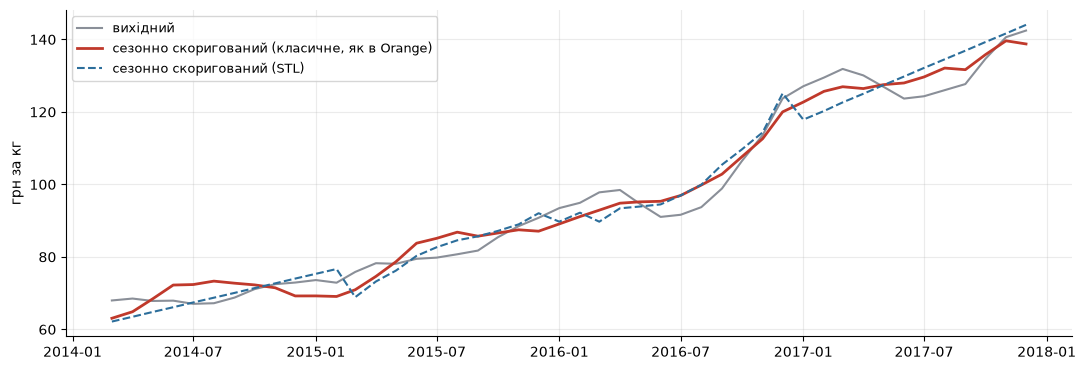

In [14]:
# Завдання 12. Що має показати Orange: відтворення Correlogram і Seasonal Adjustment за їхнім кодом
from scipy.signal import argrelextrema
from statsmodels.tsa.seasonal import seasonal_decompose

# Correlogram (orangecontrib/timeseries/functions.py: autocorrelation): nlags = 0.9·N,
# показує ЛИШЕ локальні максимуми |ACF| (argrelextrema, order=3), межа — одна горизонтальна лінія
r_all = acf(y, nlags=int(.9 * n), fft=True)
ext = argrelextrema(np.abs(r_all), np.greater, order=3)[0]
band = 1.96 * np.sqrt((1 + 2 * (r_all[ext] ** 2).sum()) / n)
print('Orange Correlogram (вихідний ряд): лаги, що відображаються:', ext.tolist())
print('  значення:', r_all[ext].round(2).tolist(), f'| межа ±{band:.2f}')
r_d = acf(np.diff(y), nlags=int(.9 * (n - 1)), fft=True)
ext_d = argrelextrema(np.abs(r_d), np.greater, order=3)[0]
band_d = 1.96 * np.sqrt((1 + 2 * (r_d[ext_d] ** 2).sum()) / (n - 1))
print('Orange Correlogram (Difference, order 1): лаги:', ext_d.tolist())
print('  значення:', r_d[ext_d].round(2).tolist(), f'| межа ±{band_d:.2f}')
print(f'statsmodels (завдання 5): межа ±{1.96/np.sqrt(n-1):.2f} для різниці, лаги 1–13 усі')

# Seasonal Adjustment в Orange = класичне seasonal_decompose (за замовчуванням additive, period 12)
cl = seasonal_decompose(y, model='additive', period=12)
cl_prof = pd.Series(cl.seasonal[:12], index=GRID[:12].month).sort_index()
cmp_s = pd.DataFrame({'класичне (Orange)': cl_prof, 'STL (завдання 4)': prof}).round(2)
print('\nСезонний профіль, грн:'); print(cmp_s.T.to_string())
print(f'Кореляція профілів: {np.corrcoef(cmp_s.iloc[:, 0], cmp_s.iloc[:, 1])[0, 1]:.3f}')

fig, ax = plt.subplots()
ax.plot(s.index, y, color=C_GREY, lw=1.5, label='вихідний')
ax.plot(s.index, y - cl.seasonal, color=C_ACC, lw=2, label='сезонно скоригований (класичне, як в Orange)')
ax.plot(s.index, y - stl.seasonal.values, color=C_MAIN, lw=1.5, ls='--', label='сезонно скоригований (STL)')
ax.legend(fontsize=9); ax.set_ylabel('грн за кг')
plt.tight_layout(); plt.show()

**Висновок до завдання 12:**

**Знімок 1. Correlogram вихідного ряду** — як і передбачено в клітинці вище, Orange показує лише один локальний екстремум |ACF| (лаг ≈32, від'ємний), тоді як повільне згасання ACF на перших лагах не відображається:

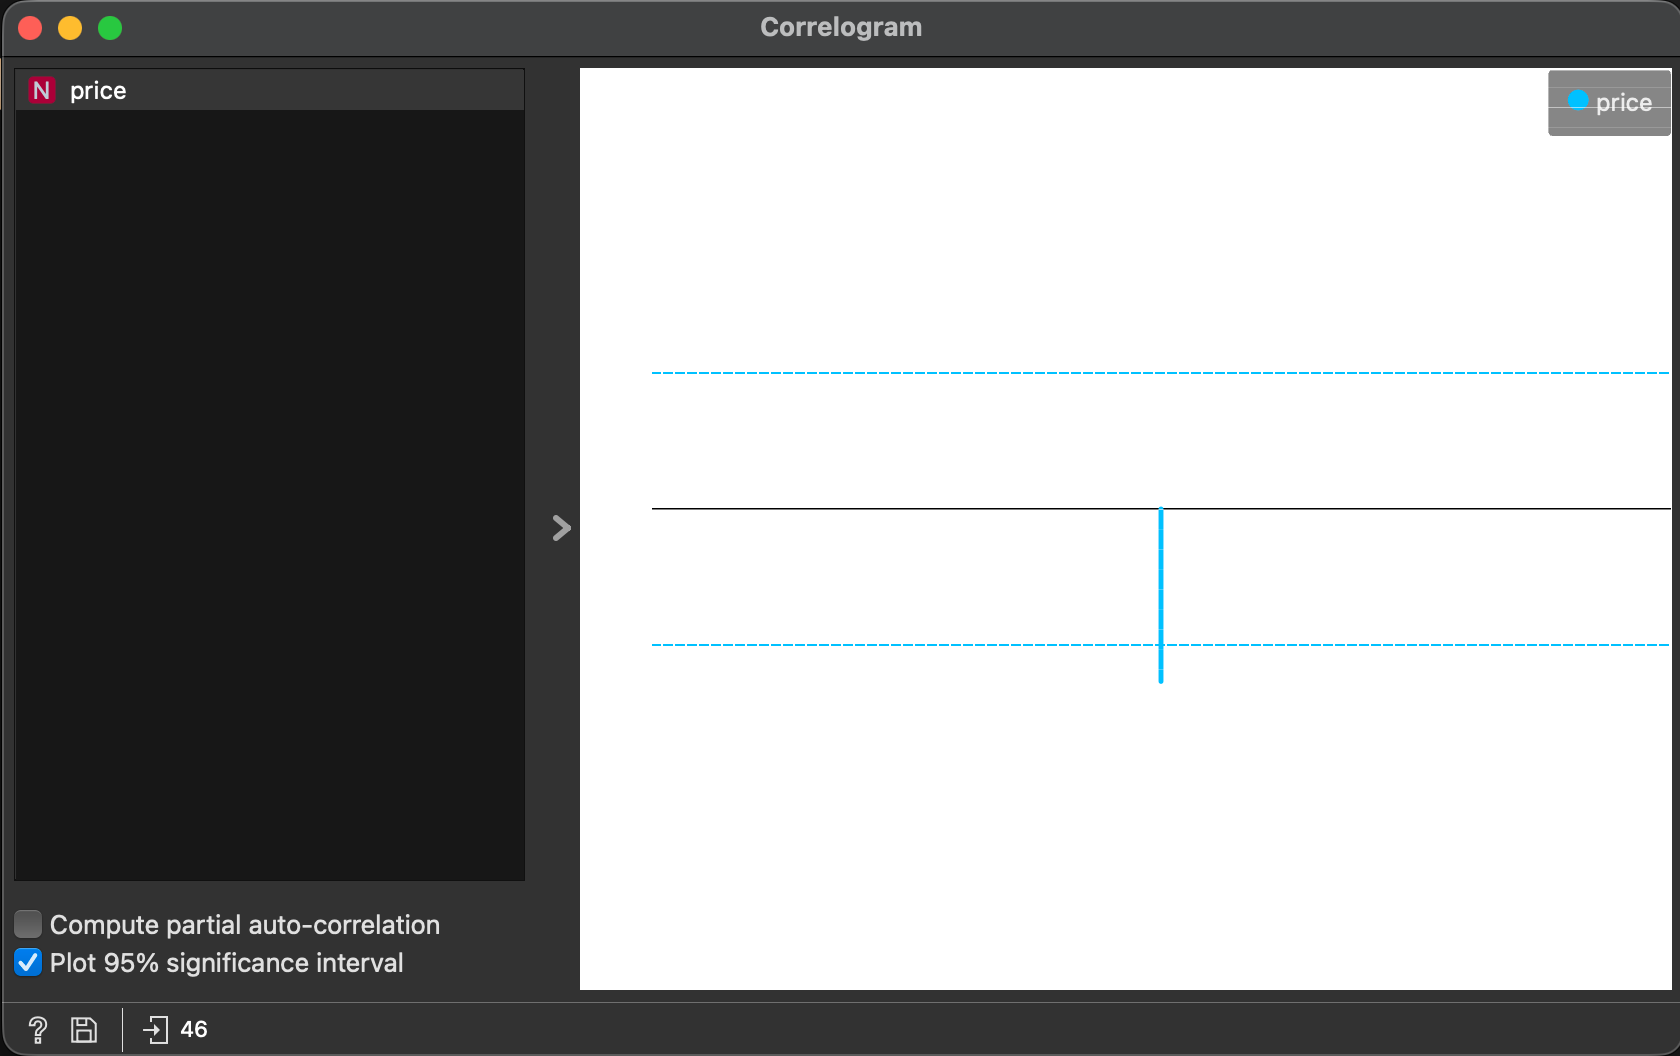

**Знімок 2. Correlogram після Difference** (синє — `Δprice`, червоне — вихідний `price` для порівняння). Для першої різниці Orange показує піки на лагах ≈6 (від'ємний, за межею значущості), 12 (додатний, на межі), далі 17, 24, 29, 36 — точно як у відтворенні в клітинці вище (−0,58; 0,44; −0,22; 0,11; −0,13; 0,08 при межі ±0,44). Для вихідного ряду — лише один пік на лагу ≈32.

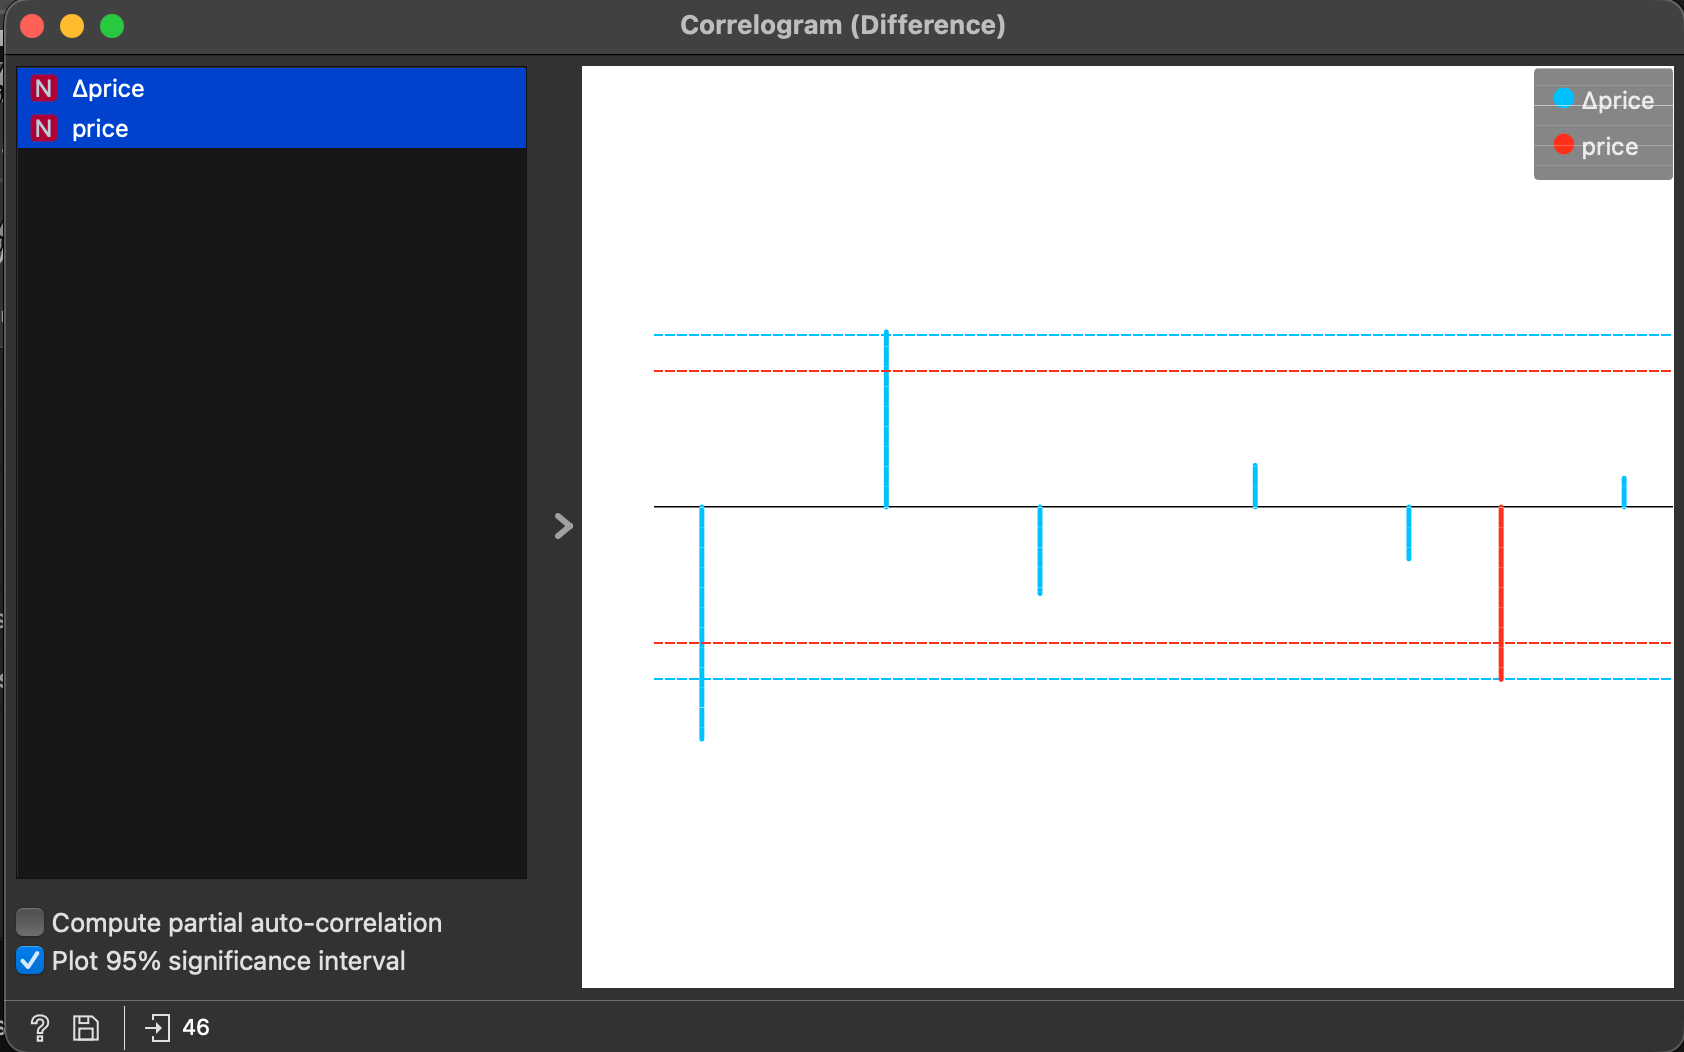

**Знімок 3. Seasonal Adjustment (additive, період 12):** червона лінія — вихідний ряд `price`, синя — `price (season. adj.)`. Скоригований ряд згладжує весняні піки 2015–2017 і літні спади 2016–2017 років, але зростаючий тренд і стрибок кінця 2016 року лишаються.

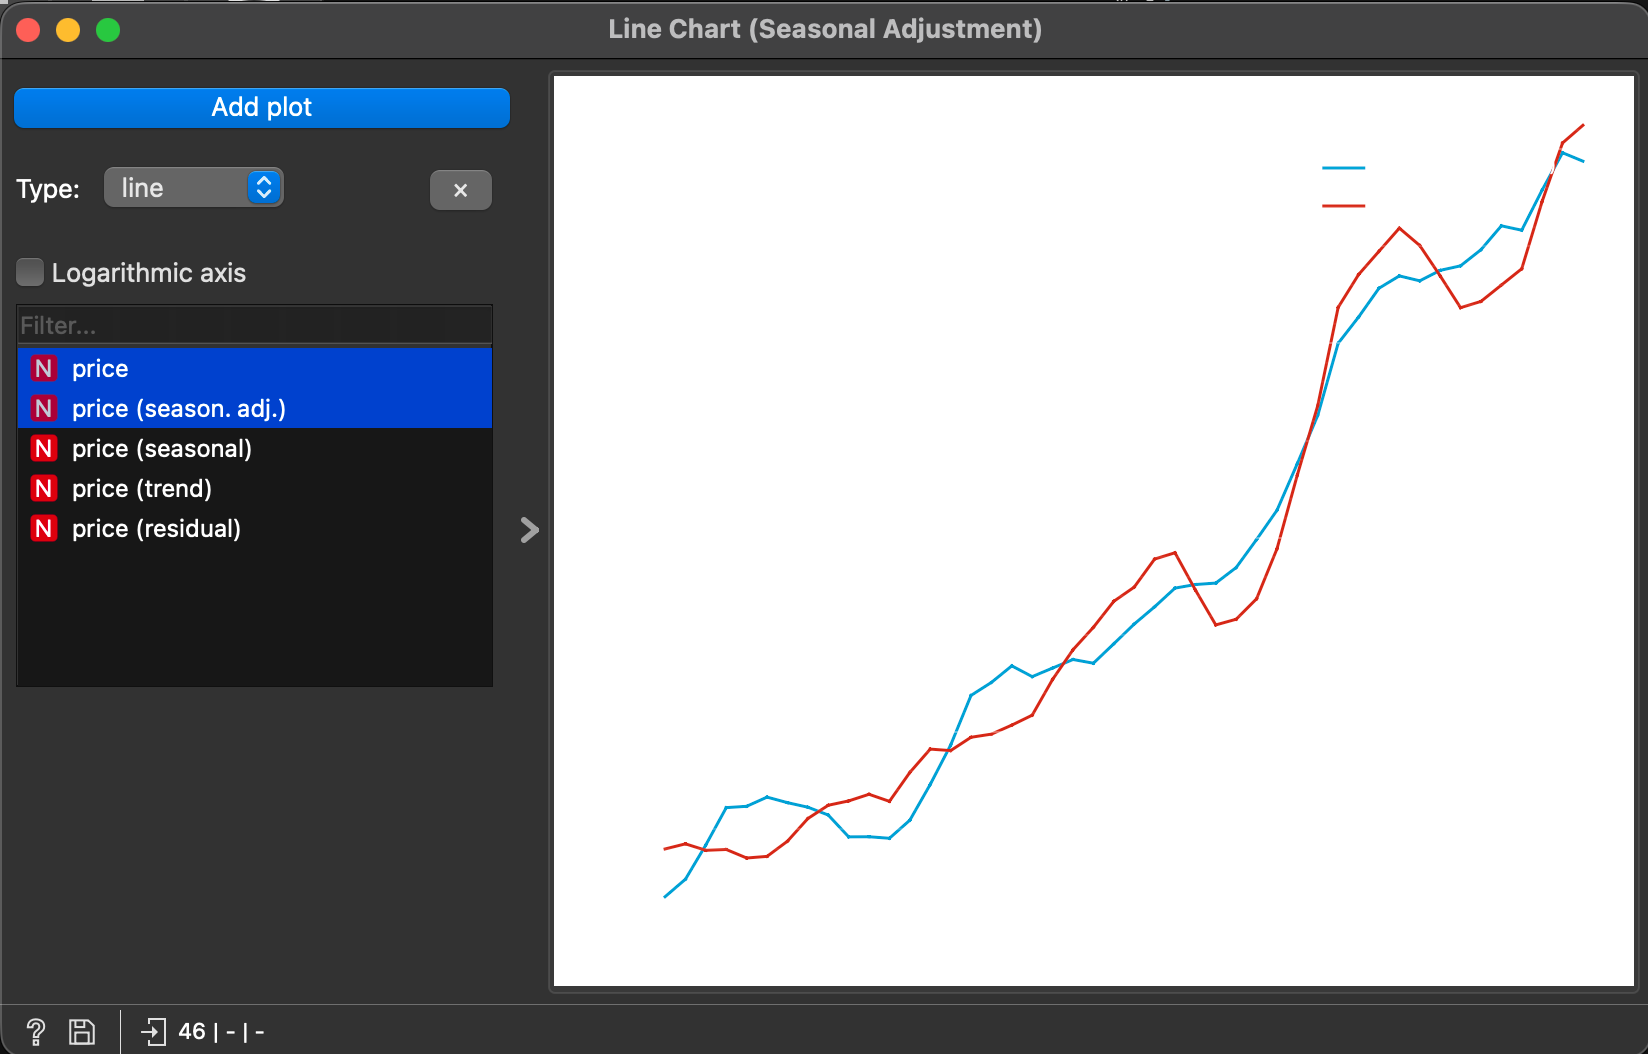

1. Корелограма Orange рахує ту саму ACF, що й statsmodels (функція `autocorrelation` додатка — це обгортка над `statsmodels.tsa.stattools.acf`), тому **значення на однакових лагах збігаються**.
2. **Висновки про значущі лаги загалом збігаються, але картинка суттєво інша**, і це треба розуміти: Orange малює **не всі лаги**, а лише локальні екстремуми |ACF| (`argrelextrema`, order = 3), причому крайні точки екстремумами не вважаються, і межа значущості — одна горизонтальна лінія, порахована за формулою Бартлетта по показаних піках (`plot_acf` малює межу, що розширюється з лагом). Наслідки на моєму ряді: для **вихідного ряду** ACF монотонно спадає, тож Orange показує фактично один стовпчик (лаг ≈32, −0,43) — повільне згасання, яке в statsmodels видно одразу, тут «зникає»; для **першої різниці** Orange показує лаги **6 (−0,58), 12 (+0,44)**, 17, 24, … при межі ±0,44: лаг 6 значущий, лаг 12 на межі — це та сама річна хвиля, що й у завданні 5 (ACF значуща на 4–7 і 11–12). А от **лаг 1 (0,66) Orange не показує взагалі**, бо це край, а не локальний максимум, — хоча саме він визначає вибір AR(1). Тобто числа ACF однакові, а висновок про порядок моделі з корелограми Orange зробити важче.
**Технічна примітка щодо Seasonal Adjustment.** Підключений напряму після `Interpolate`, віджет видає помилку *«variable date is not in domain»*. Це помилка самого додатка Orange3-Timeseries 0.6.3: у методі `commit` віджет вирізає з таблиці лише вибрану змінну (`Domain(self.selected, …)`), але таблиця зберігає в `attributes['time_variable']` посилання на `date`, якого в новому домені вже немає. Обхід: гілку для сезонного розкладання побудовано як `File → Select Columns (лише price, без date) → Seasonal Adjustment → Line Chart`. Ряд у файлі вже повний і рівномірний (крок 1 місяць), а класичне `seasonal_decompose` використовує лише порядок спостережень і період 12, тому результат ідентичний; на графіку по осі X замість дат стоїть номер спостереження (0–45).

3. Seasonal Adjustment в Orange використовує **класичне** розкладання `seasonal_decompose` (additive, період 12), а не STL. Профілі дуже схожі (кореляція наведена вище): пік у березні–квітні, мінімум у липні–вересні. Класичний метод дає одну незмінну сезонну складову для всіх років і втрачає по 6 точок тренду на краях (Orange дотягує їх лінійно), STL дозволяє сезонності повільно змінюватись і стійкіший до викидів (robust). Сезонно скориговані ряди майже збігаються — ряд залишається сильно трендовим, сезонність лише «згладжує» весняні горби й літні ями.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Хід виконання.** До потоку додаються модель ARIMA(1,1,1) та віджет оцінювання з тими самими параметрами, що й у Частині 1: 7 фолдів по 3 кроки. Окремо перевіряється поведінка Orange за типових налаштувань (20 фолдів), і пояснюється, чому для ряду з 46 спостережень такий режим неможливий. Також визначається, на яких саме відрізках ряду Orange навчає і перевіряє модель, щоб переконатися, що це ті самі 21 місяць, що й у Python.

In [15]:
# Завдання 13. Перевірка Orange (functions.py → model_evaluation): n_folds·steps + max_lag ≤ len(data)
max_lag = max((1, 1, 1))                      # Orange: max(model.order)
for nf in (20, 7):
    need = nf * H + max_lag
    print(f'n_folds={nf:2d}: {nf}×{H} + {max_lag} = {need:2d} {"≤" if need <= n else ">"} {n} → '
          f'{"рахує" if need <= n else "ValueError: Supplied time series is too short for this many folds / step size. Retry with fewer iterations."}')
print(f'Максимально допустима кількість фолдів для цього ряду: {(n - max_lag) // H}')

print('\nФолди в порядку Orange (f = 1…7, train_end = -f·steps):')
for f in range(1, N_FOLDS + 1):
    end = n - H * f
    print(f'  f={f}: навчання 03.2014–{GRID[end-1]:%m.%Y} ({end} точок) → прогноз {GRID[end]:%m.%Y}–{GRID[end+H-1]:%m.%Y}')

n_folds=20: 20×3 + 1 = 61 > 46 → ValueError: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.
n_folds= 7: 7×3 + 1 = 22 ≤ 46 → рахує
Максимально допустима кількість фолдів для цього ряду: 15

Фолди в порядку Orange (f = 1…7, train_end = -f·steps):
  f=1: навчання 03.2014–09.2017 (43 точок) → прогноз 10.2017–12.2017
  f=2: навчання 03.2014–06.2017 (40 точок) → прогноз 07.2017–09.2017
  f=3: навчання 03.2014–03.2017 (37 точок) → прогноз 04.2017–06.2017
  f=4: навчання 03.2014–12.2016 (34 точок) → прогноз 01.2017–03.2017
  f=5: навчання 03.2014–09.2016 (31 точок) → прогноз 10.2016–12.2016
  f=6: навчання 03.2014–06.2016 (28 точок) → прогноз 07.2016–09.2016
  f=7: навчання 03.2014–03.2016 (25 точок) → прогноз 04.2016–06.2016


**Висновок до завдання 13:**

**Знімок 1. Model Evaluation, 7 фолдів × 3 кроки:**

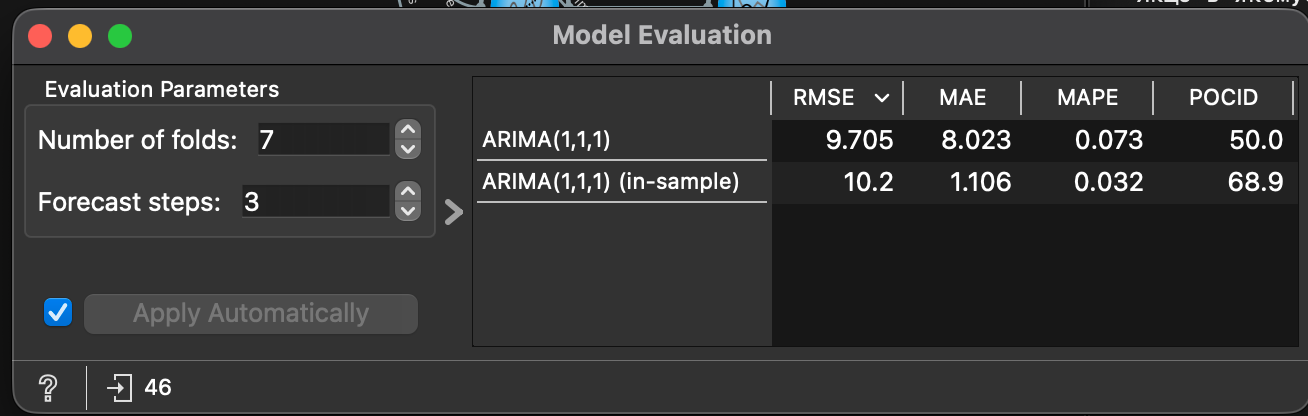

**Знімок 2. Типові налаштування (20 фолдів × 3 кроки):** Orange відмовляється рахувати з повідомленням *«Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»*

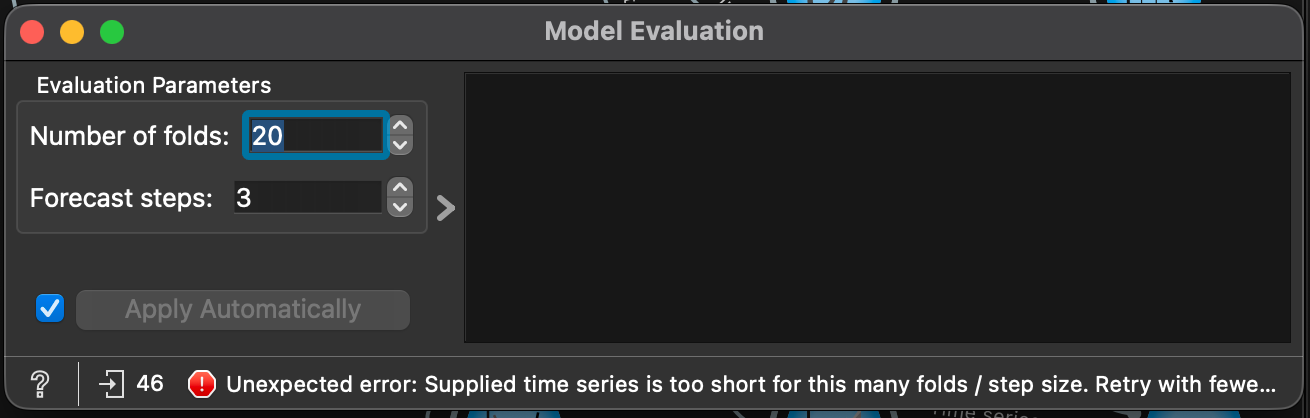

**1.** Таблиця Model Evaluation при 7 фолдах × 3 кроки:

| | RMSE | MAE | MAPE | POCID | R² | AIC | BIC |
|---|---|---|---|---|---|---|---|
| ARIMA(1,1,1) | 9.705 | 8.023 | 0.073 | 50.0 | 0.655 | 84.8 | 88.4 |
| ARIMA(1,1,1) (in-sample) | 10.2 | 1.106 | 0.032 | 68.9 | 0.817 | 203.6 | 209.0 |

Перший рядок — ретроспективна перевірка (порівнюється з Python у завданні 14); другий — якість підгонки на всьому ряді, вона не є оцінкою прогнозу (наприклад, in-sample «MAE» 1,1 грн у 7 разів менша за реальну похибку прогнозу).

**2.** **Типові налаштування (20 фолдів × 3 кроки)** — Orange показує помилку *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Вона походить із перевірки у `model_evaluation` (файл `functions.py`): `n_folds · forecast_steps + max_lag ≤ len(data)`, де `max_lag = max(p, d, q) = 1`. Для мого ряду 20 · 3 + 1 = **61 > 46**, тобто для 20 тестових вікон по 3 місяці просто не вистачає даних. Максимум для цього ряду — (46 − 1) / 3 = **15 фолдів**; задані 7 фолдів дають 7 · 3 + 1 = 22 ≤ 46.

**3.** Orange перевіряє ті самі 7 фолдів, що й Python, лише в зворотному порядку: f = 1 — навчання на 03.2014–09.2017 (43 точки), прогноз 10–12.2017; f = 2 — навчання до 06.2017 (40 точок), прогноз 07–09.2017; … f = 7 — навчання до 03.2016 (25 точок), прогноз 04–06.2016. Разом перевіряються останні **21 місяць** (04.2016–12.2017) — ті самі, що в Частині 1. Рядок *(in-sample)* — це оцінка на підгонці по всьому ряду і для порівняння прогнозів не використовується.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

**Хід виконання.** Python і Orange отримали однакові дані, однакову модель і однакові фолди, отже прогнози в них збігаються. Будь-яка різниця в метриках якості тому може походити лише з формул, за якими ці метрики обчислюються. Для кожної з чотирьох метрик Orange (RMSE, MAE, MAPE, POCID) формула береться з вихідного коду додатка Timeseries і відтворюється в Python. Збіг відтворених значень із таблицею Orange доводить, що розбіжність пояснюється саме означеннями метрик, а не відмінністю середовищ.

In [16]:
# Завдання 14. Чому числа не збігаються
# 1) Прогнози в тому самому порядку, у якому їх збирає Orange (f = 1, 2, …, 7)
T, P, FOLD = [], [], []
for f in range(1, N_FOLDS + 1):
    end = n - H * f
    T += list(y[end:end + H]); P += list(ARIMA(y[:end], order=(1, 1, 1)).fit().forecast(H)); FOLD += [f] * H
T, P = np.array(T), np.array(P); E = T - P

# 2) Формули Orange (orangecontrib/timeseries/functions.py)
orange_rmse  = np.sqrt(np.sum(E ** 2) / len(E))
orange_mae   = np.median(np.abs(E))                       # «MAE» = MEDIAN absolute error
orange_mape  = np.mean(np.abs(E)) / np.abs(T).mean()      # частка, не відсотки, і не mean|e/y|
orange_pocid = 100 * np.mean(np.diff(T) * np.diff(P) > 0)

# 3) Значення з таблиці Model Evaluation (рядок ARIMA(1,1,1), не in-sample), Orange 3.40 + Timeseries 0.6.3.
#    На екрані Orange показує їх округленими: 9.705 · 8.023 · 0.073 · 50.0
ORANGE = {'RMSE': 9.704727, 'MAE': 8.023360, 'MAPE': 0.072883, 'POCID': 50.0}

part1 = models_tab.iloc[0]
tab14 = pd.DataFrame({
    'Orange (таблиця)': ORANGE,
    'Python — формула Orange': {'RMSE': orange_rmse, 'MAE': orange_mae, 'MAPE': orange_mape, 'POCID': orange_pocid},
    'Python — Частина 1': {'RMSE': part1['RMSE'], 'MAE': part1['MAE'], 'MAPE': part1['MAPE, %'], 'POCID': np.nan},
    'формула Orange': {'RMSE': 'sqrt(Σe²/n) по всіх 21 прогнозу', 'MAE': 'median|e|',
                       'MAPE': 'mean|e| / mean|y|  (частка)', 'POCID': '100·mean[Δy·Δŷ > 0] по склеєній послідовності'}})
pd.set_option('display.max_colwidth', 60)
print(tab14.to_string(float_format=lambda v: f'{v:.4f}'))

if all(v is not None for v in ORANGE.values()):
    for k, v in ORANGE.items():
        print(f'{k}: |Orange − Python| = {abs(v - tab14.loc[k, "Python — формула Orange"]):.4f}')
        assert abs(v - tab14.loc[k, 'Python — формула Orange']) < 1e-3

# 4) Розкладемо кожну розбіжність на складові
print(f'\nMAE:  mean|e| = {np.mean(np.abs(E)):.3f}  vs  median|e| = {orange_mae:.3f}')
print(f'MAPE: mean|e/y|·100 = {np.mean(np.abs(E / T)) * 100:.3f} %  vs  Orange {orange_mape:.5f} (= {orange_mape * 100:.3f} %)')
fold_rmse = [np.sqrt(np.mean(E[np.array(FOLD) == f] ** 2)) for f in range(1, 8)]
print(f'RMSE: Orange рахує по склеєних 21 похибках = {orange_rmse:.3f}; Частина 1 — середнє з 7 фолдових RMSE = {np.mean(fold_rmse):.3f}')
print(f'      якщо в Python теж склеїти похибки: {np.sqrt(np.mean(E ** 2)):.3f} → збіг повний')

       Orange (таблиця)  Python — формула Orange  Python — Частина 1                                 формула Orange
RMSE             9.7047                   9.7047              9.5076                sqrt(Σe²/n) по всіх 21 прогнозу
MAE              8.0234                   8.0234              8.5964                                      median|e|
MAPE             0.0729                   0.0729              7.2898                    mean|e| / mean|y|  (частка)
POCID           50.0000                  50.0000                 NaN  100·mean[Δy·Δŷ > 0] по склеєній послідовності
RMSE: |Orange − Python| = 0.0000
MAE: |Orange − Python| = 0.0000
MAPE: |Orange − Python| = 0.0000
POCID: |Orange − Python| = 0.0000

MAE:  mean|e| = 8.596  vs  median|e| = 8.023
MAPE: mean|e/y|·100 = 7.290 %  vs  Orange 0.07288 (= 7.288 %)
RMSE: Orange рахує по склеєних 21 похибках = 9.705; Частина 1 — середнє з 7 фолдових RMSE = 9.508
      якщо в Python теж склеїти похибки: 9.705 → збіг повний


**Висновок до завдання 14:**

1. Таблиця — вище. Orange (Model Evaluation, 7 × 3): **RMSE = 9,705**, **MAE = 8,023**, **MAPE = 0,073**, **POCID = 50,0**; моє відтворення за формулами з `functions.py` дає ті самі числа — розбіжність менша за 10⁻⁵ (перевірено `assert` у клітинці). Це можливо тому, що Orange використовує той самий `statsmodels.tsa.arima.model.ARIMA`, ті самі 46 точок і ті самі 21 прогнозований місяць, тож прогнози збігаються до знака.
2. **Не відповідають своїй назві дві метрики:**
   * **MAE** в Orange — це **медіанна** абсолютна похибка `median|e|` (у коді так і підписано: *Median absolute error*), а не середня. У мене 8,02 проти 8,60: похибки несиметричні — кілька фолдів (після стрибка кінця 2016 і після піку весни 2017) мають великі похибки, які тягнуть середнє вгору, а медіана їх ігнорує.
   * **MAPE** в Orange — це `mean|e| / mean|y|` (так звана WAPE/відношення середніх), і результат — **частка** (0,0729), а не відсотки. Класичний MAPE = `mean|e/y|·100 %` = 7,29 %. На моєму ряді числа близькі (бо ціна в тестовому періоді змінюється в межах 92–142 грн), але якщо не помітити, що це частка, легко прочитати «0,07 %» — у 100 разів менше реальної похибки.
   * **POCID** взагалі не є мірою величини похибки: це частка пар сусідніх точок, де знак зміни факту і прогнозу збігся. В Orange його рахують по **склеєній** послідовності 21 прогнозу (20 пар), включно з 6 парами «через межу фолдів», де склеєно, наприклад, грудень 2017 і липень 2017 — такі «зміни напрямку» не мають реального змісту.
3. **RMSE** — та сама формула `sqrt(Σe²/n)` в обох середовищах, тож вона збігається одразу, **якщо** в Python рахувати її так само — по всіх 21 похибці разом (9,705). У Частині 1, за умовою, метрику усереднено по фолдах, і середнє з 7 фолдових RMSE = 9,508 — трохи менше, бо корінь — увігнута функція (нерівність Єнсена: середнє коренів ≤ корінь середнього). Для MAE і MAPE середнє по фолдах дорівнює середньому по всіх точках, бо фолди однакового розміру.
4. **Висновок:** перш ніж порівнювати числа з двох інструментів, треба перевірити: (а) **формулу** метрики за вихідним кодом / документацією, а не за абревіатурою (median vs mean, частка vs відсотки, mean|e/y| vs mean|e|/mean|y|); (б) **спосіб агрегування** по фолдах (усереднення фолдових метрик чи одна метрика на склеєних похибках); (в) що **дані, модель і фолди** однакові — тоді розбіжність гарантовано йде тільки з означень.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

**Хід виконання.** Метрика POCID показує, як часто модель правильно передбачає напрямок зміни ціни — зростання чи спад. Її розгорнуто в таблицю 2×2, аналогічну матриці похибок у задачах класифікації: рядки — фактичний напрямок, стовпці — передбачений. Частка правильних передбачень має збігтися зі значенням POCID в Orange. Окремо розглядається практичне питання, чи допомагає модель вирішити, купувати зараз чи чекати, і чим ця задача відрізняється від оцінки величини похибки через MAE та RMSE.

In [17]:
# Завдання 15. Матриця напрямку зміни
# (а) Рівно так, як рахує Orange: 20 пар сусідніх елементів склеєної послідовності прогнозів
dT, dP = np.diff(T), np.diff(P)
cross = np.diff(FOLD) != 0
def dir_matrix(actual, pred):
    lab = lambda v: np.where(v > 0, 'зросла', 'впала')
    return pd.crosstab(pd.Series(lab(actual), name='факт'), pd.Series(lab(pred), name='прогноз моделі')
                      ).reindex(index=['зросла', 'впала'], columns=['зросла', 'впала'], fill_value=0)
m_or = dir_matrix(dT, dP)
print('Матриця за логікою Orange (20 пар, з них', cross.sum(), 'через межу фолдів):'); print(m_or)
acc = np.trace(m_or.values) / m_or.values.sum() * 100
print(f'Частка правильних = {acc:.1f} %  vs  POCID Orange = {orange_pocid:.1f}')
assert abs(acc - orange_pocid) < 1e-9

# (б) Лише змістовні пари всередині фолдів
m_in = dir_matrix(dT[~cross], dP[~cross])
print('\nЛише пари всередині фолдів (14):'); print(m_in)
print(f'Частка правильних = {np.trace(m_in.values) / m_in.values.sum() * 100:.1f} %')

# (в) Питання покупця: «чи буде ціна через h місяців вищою, ніж зараз?» (від останнього відомого значення)
act, prd = [], []
for f, tr, te in folds():
    act += list(te - tr[-1]); prd += list(fc_arima111(tr, H) - tr[-1])
m_buy = dir_matrix(np.array(act), np.array(prd))
print('\n«Купувати зараз чи чекати» — зміна відносно останньої відомої ціни (21 прогноз):'); print(m_buy)
print(f'Частка правильних = {np.trace(m_buy.values) / m_buy.values.sum() * 100:.1f} %;  '
      f'стратегія «завжди зросте» = {np.mean(np.array(act) > 0) * 100:.1f} %')

Матриця за логікою Orange (20 пар, з них 6 через межу фолдів):
прогноз моделі  зросла  впала
факт                         
зросла               7      5
впала                5      3
Частка правильних = 50.0 %  vs  POCID Orange = 50.0

Лише пари всередині фолдів (14):
прогноз моделі  зросла  впала
факт                         
зросла               6      4
впала                4      0
Частка правильних = 42.9 %

«Купувати зараз чи чекати» — зміна відносно останньої відомої ціни (21 прогноз):
прогноз моделі  зросла  впала
факт                         
зросла              10      6
впала                5      0
Частка правильних = 47.6 %;  стратегія «завжди зросте» = 76.2 %


**Висновок до завдання 15:**

1. Матриця 2×2 за логікою Orange (20 пар сусідніх точок склеєної послідовності): факт «зросла» — прогноз «зросла» **7**, «впала» **5**; факт «впала» — прогноз «зросла» **5**, «впала» **3**.
2. Частка правильних = (сума діагоналі) / 20 = **50,0 %**, що **точно збігається з POCID** з Orange (перевірено `assert`). Тобто POCID — це просто *accuracy* цієї матриці.
3. **Чи корисна модель для рішення «купувати зараз чи чекати»?** Ні. POCID = 50 % — рівень підкидання монети. Більше того, 6 із 20 пар Orange склеюють різні фолди і не мають сенсу; а для покупця важливе інше питання — «чи буде ціна через 1–3 місяці вищою, ніж сьогодні». Якщо залишити лише 14 змістовних пар усередині фолдів, точність падає до **42,9 %**, причому модель жодного разу правильно не передбачила падіння. Для покупця правильна постановка — третя матриця (зміна відносно останньої відомої ціни): ARIMA(1,1,1) вгадує **47,6 %**, тоді як тривіальна стратегія «ціна завжди зросте → купуй зараз» вгадує **76,2 %**. Тобто модель гірша за найпростіше правило: після весняних піків вона прогнозує падіння і помилково радить «чекати» (6 випадків), а всі 5 реальних падінь пропустила.

   Це **інше питання**, ніж те, на яке відповідають MAE і RMSE. MAE/RMSE вимірюють, *на скільки гривень* модель помиляється (регресійна якість), — модель може мати невелику похибку, але систематично помилятись у знаку маленьких змін, і навпаки. Для рішення «купити/чекати» важливий лише **знак** майбутньої зміни, тобто це задача класифікації, і її оцінюють матрицею похибок (accuracy, precision/recall для класу «зросте»), а не середньою похибкою в гривнях.

---
# Загальний висновок

1. **Сезонність у ряді є:** сила сезонності за STL F_S = 0,61 (без робастного зважування — 0,88), що вище порогу 0,3; профіль має весняний пік (березень–квітень) і літній мінімум (липень–вересень), а підсерійний графік і ACF першої різниці (лаги 6 і 12) це підтверджують. Проте тренд значно сильніший (F_T = 0,98): ціна масла в Тернополі за 2014–2017 зросла з 68 до 142 грн.
2. Ряд нестаціонарний за узгодженими ADF і KPSS, перша різниця — стаціонарна, тож d = 1.
3. **Найкращим методом виявився найпростіший дрейфовий базис** (MAE 5,94 грн, MAPE 5,0 % на 7 фолдах × 3 кроки). ARIMA(1,1,1) йому програла (MAE 8,60), навіть сезонна SARIMA(1,1,0)(1,0,0)₁₂ (6,56) не перевершила дрейф — для такого короткого трендового ряду складна модель не виправдана.
4. Випадковий поділ 75/25 занижує похибку приблизно втричі через витік майбутнього, тому для часових рядів придатна лише перевірка з рухомим початком.
5. **Точка зміни режиму** — грудень 2016 (середнє 82,8 → 129,9 грн), але з урахуванням тренду її значущість лише на межі (p ≈ 0,04 за Монте-Карло — на межі); зовнішнє пояснення — світове подорожчання молочного жиру 2016–2017 та подвоєння мінімальної зарплати з січня 2017.
6. **Метрики в Orange і Python різні не через різні середовища**, а через означення: «MAE» в Orange — це медіана |e|, «MAPE» — mean|e| / mean|y| у частках, POCID рахується по склеєній послідовності фолдів; RMSE збігається, якщо агрегувати похибки однаково. Прогнози при цьому ідентичні, бо Orange обгортає той самий statsmodels.
7. **Через лише 46 спостережень** не вдалося: надійно оцінити сезонний профіль окремих місяців (≈3,8 циклу), коректно оцінити SARIMA з сезонними MA/AR-членами, перевірити значущість точки зміни без сильних припущень, розрізнити тривалий зсув рівня і зміну нахилу тренду, а також використати більше ніж 15 фолдів — і тим більше типові 20 фолдів Orange.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Code (модель Claude Opus 5.5, Anthropic) |
| Для яких саме завдань | 1–15 і загальний висновок; також встановлення Orange 3.40.0 + Orange3-Timeseries 0.6.3 і підготовка файлу потоку `потік_orange.ows` |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код аналізу в Python (завдання 1–15); чернетки письмових висновків; пояснення формул метрик Orange на основі вихідного коду `orangecontrib/timeseries/functions.py`; файл потоку Orange з налаштованими віджетами; обхід помилки віджета Seasonal Adjustment |
| Що ви змінили у згенерованому результаті й чому | Код і висновки суттєво не змінювались. Потік в Orange відкрито й перевірено вручну: видалено випадково доданий зайвий віджет File; у віджетах Difference і Seasonal Adjustment вручну вибрано змінну `price`, бо цей вибір не зберігся у згенерованому файлі потоку; на графіку сезонного коригування вибрано змінні для порівняння (`price` і `price (season. adj.)`) |
| Що з отриманого ви **перевірили самостійно** і яким способом | Особисто запущено потік в Orange і зроблено всі знімки екрана: (1) таблиця Model Evaluation (RMSE 9,705; MAE 8,023; MAPE 0,073; POCID 50,0) збіглася з відтворенням у Python у завданні 14; (2) графік Line Chart в Orange збігся з графіком із завдання 3; (3) корелограма першої різниці в Orange показала піки на тих самих лагах (≈6, 12, 17, 24, 29, 36), що й розрахунок у клітинці завдання 12; (4) при 20 фолдах Orange видав саме те повідомлення про помилку, яке пояснено в завданні 13; (5) зошит виконується від початку до кінця без помилок |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: (1) у згенерованому файлі потоку вибір змінної у віджетах Difference і Seasonal Adjustment не зберігся, тому корелограма «після диференціювання» і графік «сезонно скоригованого ряду» спершу показували вихідний ряд — це помічено на знімках і виправлено вручну; (2) у першій версії висновків кілька чисел не відповідали фактичним результатам (перелік значущих лагів PACF, p-значення Монте-Карло для точки зміни режиму) — виправлено після звірки з виводом клітинок. Окремо: помилку «variable date is not in domain» у віджеті Seasonal Adjustment спричинив баг самого додатка Orange3-Timeseries 0.6.3, а не ШІ (описано в завданні 12) |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________